<a href="https://colab.research.google.com/github/bulut19/super-bowl-ad-scorecard/blob/main/super_bowl_ad_scorecard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Liked but Forgotten: Scoring 2025 Super Bowl Ads from YouTube Comments

**MIS 284N Analytics for Unstructured Data, UT Austin McCombs (Fall 2026)**
**Team:** Jonathan Choi, Shehryar Syed, Samantha Feinberg, Melisa Bulut, Yash Shrivastava

A 30-second Super Bowl spot costs about **$8M**, and the most-cited scorecard, USA Today's Ad Meter, asks viewers one question: *did you like it?* We built a three-pillar scorecard from **10,547 cleaned YouTube comments** on 2025 Super Bowl ads:

1. **Likability:** net sentiment (RoBERTa and VADER) plus seven emotions
2. **Brand recall:** share of comments that name the brand or product
3. **Message fit:** semantic similarity between comments and the ad's message (sentence embeddings)

We validated the scores against **USA Today Ad Meter** and the **Kellogg Super Bowl Advertising Review**, clustered the ads into types, and identified ads that were *liked but forgotten*.

## Key Results
- Comment-based likability tracks Ad Meter closely (Spearman **+0.78** across 18 ads; **+0.82** when weighted by comment likes).
- Liking and brand recall are unrelated (**-0.17**), and neither benchmark captures recall.
- Lay's (#2 on Ad Meter), Stella Artois (#4), Instacart and WeatherTech were well liked but rarely named in comments.
- RoBERTa beat VADER on 50 hand-labeled comments (**64% vs. 44%**); VADER overstates likability.
- Removing **1,790 bot-spam comments** was essential: spam made up about a third of the Marvel trailer's comments.
- Total cost: **$0** (free open-source models on a free Colab GPU).

## Notebook Contents
| Section | Topic |
|---|---|
| Task A | Data collection (YouTube Data API v3) |
| Task B | Language exploration: bot-spam removal, word frequency, concept lift, LDA topics |
| Task C | Likability: VADER vs. RoBERTa sentiment, emotion model, hand-labeled validation |
| Task D | Brand recall: regex baseline |
| Task E | Message fit: bag-of-words vs. sentence embeddings |
| Task F | Scorecard validation, k-means ad types, liked-vs-remembered 2x2, regression |
| Task G | Recommendations, robustness check, limitations |

**To run:** place `2025ads.csv` and `ads.csv` in a `data/` folder next to this notebook and use a GPU runtime (Colab T4 works). Outputs are written to `outputs/`.

# Task A: Data Collection

We collected top-level YouTube comments for 30 videos tied to the 2025 Super Bowl (Super Bowl LIX) using the YouTube Data API v3 (`commentThreads.list`). For each video we pulled comments sorted by relevance (8,333 rows) and by time (5,660 rows), for **13,993 rows** in total.

| Video type | Count |
|---|---|
| Brand ads | 26 |
| Studio movie trailers that aired during the game | 3 |
| News report (State Farm ad withdrawal) | 1 |

The collected dataset is `2025ads.csv` (one row per comment, 15 columns including video metadata, comment text, comment likes and publish date). The raw data is not included in this repository; see the README for details.

# Task B: Explore the Language of Super Bowl Ad Comments

## Objective
Analyze the language in YouTube comments to understand what viewers
discuss about Super Bowl advertisements.

Our group collected YouTube comments for videos associated with
2025 Super Bowl advertisements. This section uses our collected
dataset, `2025ads.csv`, to explore audience discussions.

## Approach
1. Examine word frequencies to identify common discussion terms.
2. Calculate lift between concepts to measure which concepts occur
   together more often than expected.
3. Validate the lift calculation using a small example.
4. Apply topic modeling to identify 6–8 recurring discussion topics.
5. Interpret the findings and explain their relevance to our
   advertising scorecard.

In [ ]:
import os
import pandas as pd

# Folder that holds 2025ads.csv (and ads.csv for Task F).
# In Colab, upload the files to a "data" folder or point DATA_DIR to Google Drive.
DATA_DIR = "data"

df = pd.read_csv(os.path.join(DATA_DIR, "2025ads.csv"))

print(f"Number of rows: {len(df):,}")
print(f"Number of videos: {df['video_id'].nunique():,}")
print("\nColumns:")
print(df.columns.tolist())

# Preview without commenter handles.
display(df.drop(columns=["comment_author"]).head())

Number of rows: 13,993
Number of videos: 30

Columns:
['year', 'video_id', 'video_title', 'channel', 'views', 'likes', 'shares', 'video_comment_count', 'comment_rank', 'order_source', 'comment_id', 'comment_author', 'comment_text', 'comment_likes', 'comment_published']


,year,video_id,video_title,channel,views,likes,shares,video_comment_count,comment_rank,order_source,comment_id,comment_text,comment_likes,comment_published
0,2025,ZDy_h1UA_M4,Martha Stewart for Glide-Step Skechers Slip-ins,SKECHERS,1869529,785,NaN,114,1,relevance,Ugz00dXvm4xz2M_sD3t4AaABAg,This is the best commercial I've seen all year...,55,2025-04-24T22:38:05Z
1,2025,ZDy_h1UA_M4,Martha Stewart for Glide-Step Skechers Slip-ins,SKECHERS,1869529,785,NaN,114,2,relevance,UgwNmRuKKgduaCRiOlR4AaABAg,Disturbing,2,2025-08-04T09:52:38Z
2,2025,ZDy_h1UA_M4,Martha Stewart for Glide-Step Skechers Slip-ins,SKECHERS,1869529,785,NaN,114,3,relevance,Ugxg3P5GevV7xvez4794AaABAg,I was running on the treadmill at the gym and ...,15,2025-06-25T04:46:27Z
3,2025,ZDy_h1UA_M4,Martha Stewart for Glide-Step Skechers Slip-ins,SKECHERS,1869529,785,NaN,114,4,relevance,UgwKs-xLGrWwymjuQDl4AaABAg,"The moment she said to drop a beat, I just kne...",1,2025-10-09T14:52:13Z
4,2025,ZDy_h1UA_M4,Martha Stewart for Glide-Step Skechers Slip-ins,SKECHERS,1869529,785,NaN,114,5,relevance,UgxoYa4pVeRMkcFeECl4AaABAg,Yasss wut is dat dance flip? The AI like conto...,1,2025-11-27T15:30:07Z


## Prepare Comments for Language Analysis

We preserve our group's original data and create a working copy for
Task B. We remove comments with missing or blank text and repeated
comment IDs so the same comment is not counted twice.

Different viewers may post identical comments. We inspect these
repetitions below and, in the next step, remove the ones that are
bot spam.

In [ ]:
# Preserve the original dataset.
comments = df.copy()
initial_rows = len(comments)

# Remove missing or blank comments.
valid_text = (
    comments["comment_text"].notna()
    & comments["comment_text"].fillna("").str.strip().ne("")
)
comments = comments.loc[valid_text].copy()
removed_empty = initial_rows - len(comments)

# Count each comment ID once.
before_dedup = len(comments)
comments = comments.drop_duplicates(subset="comment_id").copy()
removed_ids = before_dedup - len(comments)

comments["comment_text"] = comments["comment_text"].str.strip()

# Inspect repeated text within each video without removing it yet.
repeated_text = (
    comments.groupby(["video_id", "comment_text"])
    .size()
    .reset_index(name="occurrences")
    .query("occurrences > 1")
    .sort_values("occurrences", ascending=False)
)

print(f"Starting rows: {initial_rows:,}")
print(f"Missing or blank comments removed: {removed_empty:,}")
print(f"Repeated comment IDs removed: {removed_ids:,}")
print(f"Remaining comments: {len(comments):,}")
print(f"Videos represented: {comments['video_id'].nunique():,}")

print("\nMost repeated comments within a video:")
display(repeated_text.head(10))

Starting rows: 13,993
Missing or blank comments removed: 5
Repeated comment IDs removed: 0
Remaining comments: 13,988
Videos represented: 30

Most repeated comments within a video:


,video_id,comment_text,occurrences
8077,hUUszE29jS0,"Awesome video, looking forward to the next one!",116
8357,hUUszE29jS0,"Fantastic video, really appreciate your effort!",111
8446,hUUszE29jS0,Great video! Really enjoyed it.,110
9839,hUUszE29jS0,"Thank you for this video, very enlightening!",109
10213,hUUszE29jS0,"This was super helpful, thanks!",106
7996,hUUszE29jS0,Amazing content as always!,104
9174,hUUszE29jS0,"Loved this video, keep up the great work!",100
9173,hUUszE29jS0,"Loved the content, keep it coming!",99
10305,hUUszE29jS0,"Very well done, appreciate this video!",99
10206,hUUszE29jS0,"This video was amazing, learned a lot.",99


## Remove Bot Spam

The repeated comments above are not real reactions. The Marvel trailer
received about 1,700 copies of 17 generic messages, such as "Great video!
Really enjoyed it." Each message was posted roughly 100 times by different
accounts, and none of them mention the ad. The same messages also appear
on the Jeep ad and a few other videos.

We remove them before any analysis because they would inflate praise
words (such as "great" and "love"), distort the topics, and make the
Marvel trailer look far more positive in the likability scores (Task C).

We use three transparent rules:

1. **Template text:** any exact comment text that appears 20 or more
   times across the dataset and contains letters. Real reactions rarely
   repeat word for word that often; the threshold of 20 sits far above
   the most repeated genuine text and far below the bot messages
   (about 85 to 130 copies each).
2. **Known variants:** four lower-frequency messages in the same
   "tutorial praise" style, found by reading comments that mention words
   like "video", "content" or "tips" ("Really appreciate the insights in
   this video.", for example).
3. **Bot accounts:** every comment from an account that posted a template
   or variant, since those accounts are automated.

We keep short repeated reactions such as "❤" or "Stitch!", because
different viewers can genuinely post the same short reaction. The letter
requirement in rule 1 keeps emoji-only comments.

An alternative is near-duplicate detection (for example, cosine similarity
between comments), which could catch reworded spam. We chose exact rules
because the spam here is copied word for word and exact rules are easy to
check. A few other spam comments remain (for example, crypto promotions and
channel self-promotion); they are rare, and we note them as a limitation.

In [ ]:
# Rule 1: exact texts repeated 20+ times across the dataset (with letters).
text_counts = comments["comment_text"].value_counts()
bot_templates = set(
    text_counts[
        (text_counts >= 20)
        & text_counts.index.str.contains(r"[A-Za-z]", regex=True)
    ].index
)

# Rule 2: lower-frequency variants found by reading similar comments.
bot_variants = {
    "Really appreciate the insights in this video.",
    "Great tips, thanks for sharing!",
    "Your videos are always so helpful, thank you!",
    "You explained everything so clearly, thank you!",
}

is_template = comments["comment_text"].isin(bot_templates | bot_variants)

# Rule 3: remove everything posted by the accounts behind those messages.
bot_accounts = set(comments.loc[is_template, "comment_author"])
is_spam = is_template | comments["comment_author"].isin(bot_accounts)

spam_removed = comments.loc[is_spam].copy()
comments = comments.loc[~is_spam].copy()

print(f"Template texts (rule 1): {len(bot_templates)}")
print(f"Bot accounts (rule 3): {len(bot_accounts):,}")
print(f"Spam comments removed: {len(spam_removed):,}")
print(f"Remaining comments: {len(comments):,}")

print("\nSpam removed by video:")
display(
    spam_removed.groupby("video_title")
    .size()
    .sort_values(ascending=False)
    .rename("spam_removed")
    .to_frame()
)

print("\nTemplate texts removed (copies in the original data):")
display(
    text_counts[list(bot_templates)]
    .sort_values(ascending=False)
    .rename("copies")
    .to_frame()
)

# Check: no template text remains, and the highest remaining repeat count.
assert not comments["comment_text"].isin(bot_templates | bot_variants).any()
remaining_repeats = comments.groupby(["video_id", "comment_text"]).size()
print(
    "Most repeated remaining comment within a video:",
    remaining_repeats.max(), "copies"
)
display(
    remaining_repeats.sort_values(ascending=False)
    .head(5)
    .rename("occurrences")
    .reset_index()
)

Template texts (rule 1): 17
Bot accounts (rule 3): 1,674
Spam comments removed: 1,790
Remaining comments: 12,198

Spam removed by video:


,spam_removed
video_title,
Marvel Studios’ Thunderbolts* | Big Game Trailer | In Theaters May 2,1698
Jeep® | Big Game | Harrison Ford x Jeep | Owner’s Manual,86
Dream Job | Google Pixel SB Commercial 2025,3
Lilo & Stitch | Stitch Runs Loose At The Big Game | In Theaters May 23,3



Template texts removed (copies in the original data):


,copies
comment_text,
"Awesome video, looking forward to the next one!",129
"Fantastic video, really appreciate your effort!",118
Great video! Really enjoyed it.,115
"Thank you for this video, very enlightening!",114
"This was super helpful, thanks!",108
Amazing content as always!,107
"Loved this video, keep up the great work!",105
"This video was amazing, learned a lot.",104
"Great job, this video was very useful!",104


Most repeated remaining comment within a video: 5 copies


,video_id,comment_text,occurrences
0,hUUszE29jS0,❤,5
1,hUUszE29jS0,ARMED AND DANGEROUS,4
2,gqxwX1ZYg58,Pizza hut 🍕,4
3,cDn_uFEXGXk,Love it!,4
4,gqxwX1ZYg58,First,4


## Prepare Words for Frequency Analysis

We convert comments to lowercase, remove URLs, and extract words.
We exclude common English stop words, such as “the” and “and,” because
they provide little information about discussion topics.

We preserve the original comments for interpreting results and later
concept analysis. This preparation does not identify or remove
non-English comments (see Limitations).

We use word counts as a simple, interpretable starting point.
An alternative is TF-IDF, which emphasizes words that distinguish
comments rather than words that occur most frequently.

In [ ]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = set(ENGLISH_STOP_WORDS)

def prepare_words(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = text.replace("’", "'")

    # Keep contractions together, then remove their apostrophes.
    words = re.findall(r"[a-z]+(?:'[a-z]+)*", text)
    words = [word.replace("'", "") for word in words]

    return [
        word for word in words
        if len(word) > 2 and word not in stop_words
    ]

comments["tokens"] = comments["comment_text"].apply(prepare_words)
comments["text_for_topics"] = comments["tokens"].apply(" ".join)

print(f"Comments prepared: {len(comments):,}")
print(
    "Comments with no remaining words:",
    comments["tokens"].apply(len).eq(0).sum()
)

Comments prepared: 12,198
Comments with no remaining words: 376


## Word Frequency

We summarize common words using two measures:

- **Total occurrences:** How many times a word appears across comments.
- **Comments containing the word:** How many comments mention it,
  counting each word once per comment.

We rank words by the number of comments containing them to reduce
the influence of repetition within a single comment. These results
describe our collected sample; videos with more comments contribute
more to the overall counts.

In [ ]:
from collections import Counter

# Count every occurrence.
word_counts = Counter(
    word
    for tokens in comments["tokens"]
    for word in tokens
)

# Count each word only once per comment.
comment_counts = Counter(
    word
    for tokens in comments["tokens"]
    for word in set(tokens)
)

frequency_table = pd.DataFrame(
    [
        {
            "word": word,
            "total_occurrences": word_counts[word],
            "comments_containing_word": count,
            "percent_of_comments": 100 * count / len(comments)
        }
        for word, count in comment_counts.items()
    ],
    columns=[
        "word",
        "total_occurrences",
        "comments_containing_word",
        "percent_of_comments"
    ]
).sort_values(
    ["comments_containing_word", "total_occurrences", "word"],
    ascending=[False, False, True]
).reset_index(drop=True)

display(
    frequency_table.head(30).style.format(
        {"percent_of_comments": "{:.2f}%"}
    )
)

,word,total_occurrences,comments_containing_word,percent_of_comments
0,commercial,1022,966,7.92%
1,like,990,904,7.41%
2,just,816,732,6.00%
3,movie,804,717,5.88%
4,love,779,704,5.77%
5,good,677,634,5.20%
6,best,561,545,4.47%
7,dont,545,509,4.17%
8,jeep,564,467,3.83%
9,state,528,454,3.72%


### Analysis: Word Frequency

"Commercial" is the most common word (7.92% of comments), reflecting the
context of our group's dataset. Positive expressions such as "love"
(5.77%), "good" (5.20%), "best" (4.47%) and "great" (3.40%) are also
common. These counts suggest that praise is a recurring element of
discussion, but context is needed to determine sentiment.

Removing bot spam mattered here. Before the spam step, "great" appeared
in 5.96% of comments and "video" ranked among the most common words;
after it, "great" falls to 3.40% and "video" appears in only 0.71% of
comments. Much of the apparent praise came from automated messages.

Brand and entertainment references include "jeep," "marvel," "disney,"
and "stitch." Terms such as "movie" and "trailer" suggest that
entertainment-related videos contribute to the discussion.

The frequent words "state," "farm," and "insurance" require caution:
our dataset includes a news video about State Farm
withdrawing a Super Bowl commercial. Discussion of that video may
differ from reactions to an advertisement.

These results help identify candidate concepts for further analysis.
They do not establish advertising effectiveness or unaided brand
recall. Videos with more collected comments have greater influence
on the pooled frequencies.

In [ ]:
video_summary = (
    comments.groupby("video_id")
    .agg(
        video_title=("video_title", "first"),
        comment_count=("comment_id", "size")
    )
    .sort_values("comment_count", ascending=False)
    .reset_index()
)

video_summary["percent_of_comments"] = (
    100 * video_summary["comment_count"] / len(comments)
)

display(
    video_summary.head(10).style.format(
        {"percent_of_comments": "{:.2f}%"}
    )
)

,video_id,video_title,comment_count,percent_of_comments
0,hUUszE29jS0,Marvel Studios’ Thunderbolts* | Big Game Trailer | In Theaters May 2,3301,27.06%
1,-EQCWqpMEvo,State Farm Pulls Super Bowl Commercial After LA Fires,1651,13.54%
2,cDn_uFEXGXk,Jeep® | Big Game | Harrison Ford x Jeep | Owner’s Manual,1589,13.03%
3,gqxwX1ZYg58,Lilo & Stitch | Stitch Runs Loose At The Big Game | In Theaters May 23,1272,10.43%
4,K0iKgJXy_gk,Budweiser | Super Bowl LIX 'First Delivery',759,6.22%
5,-7e6g11BJc0,Dream Job | Google Pixel SB Commercial 2025,648,5.31%
6,8May3405b_o,“What If” | Big Game Spot | Disney+,401,3.29%
7,sIAnQwiCpRc,Abduction,248,2.03%
8,HLw6ZovMpLI,A New Era in Connectivity – T-Satellite | T-Mobile,248,2.03%
9,tU_vZpbnYF4,REESE'S | Don't Eat Lava,224,1.84%


## Refine the Analysis Sample

Even after removing spam, four videos contributed 64.06% of all
comments. This means the pooled word frequencies were strongly
influenced by a small number of videos.

We exclude the State Farm news report because it discusses an ad's
withdrawal rather than presenting the advertisement itself. We also
randomly select up to 300 comments per remaining video, using a fixed
random seed so the selection is reproducible.

We considered using all collected comments, but chose this cap to
reduce the influence of videos with much larger comment collections.
Videos with fewer than 300 comments retain all available comments,
so the sample is not equally weighted across videos.

Sampling cannot correct
biases in how the comments were originally collected.

In [ ]:
# Exclude the identified news report from Task B.
excluded_video_ids = {"-EQCWqpMEvo"}

eligible_comments = comments.loc[
    ~comments["video_id"].isin(excluded_video_ids)
].copy()

# Sort before sampling to make selection reproducible.
eligible_comments = eligible_comments.sort_values(
    ["video_id", "comment_id"]
)

analysis_comments = pd.concat(
    [
        group.sample(n=min(300, len(group)), random_state=42)
        for _, group in eligible_comments.groupby("video_id", sort=True)
    ],
    ignore_index=True
)

print(f"Comments before refinement: {len(comments):,}")
print(f"News-video comments excluded: {len(comments) - len(eligible_comments):,}")
print(f"Comments in our analysis sample: {len(analysis_comments):,}")
print(f"Videos in our analysis sample: {analysis_comments['video_id'].nunique()}")

# Recalculate frequencies using the refined sample.
word_counts = Counter(
    word
    for tokens in analysis_comments["tokens"]
    for word in tokens
)

comment_counts = Counter(
    word
    for tokens in analysis_comments["tokens"]
    for word in set(tokens)
)

frequency_table = pd.DataFrame(
    [
        {
            "word": word,
            "total_occurrences": word_counts[word],
            "comments_containing_word": count,
            "percent_of_comments": 100 * count / len(analysis_comments)
        }
        for word, count in comment_counts.items()
    ]
).sort_values(
    ["comments_containing_word", "total_occurrences", "word"],
    ascending=[False, False, True]
).reset_index(drop=True)

display(
    frequency_table.head(30).style.format(
        {"percent_of_comments": "{:.2f}%"}
    )
)

Comments before refinement: 12,198
News-video comments excluded: 1,651
Comments in our analysis sample: 4,377
Videos in our analysis sample: 29


,word,total_occurrences,comments_containing_word,percent_of_comments
0,commercial,497,470,10.74%
1,like,308,282,6.44%
2,love,291,262,5.99%
3,just,286,257,5.87%
4,best,227,224,5.12%
5,good,214,199,4.55%
6,disney,243,188,4.30%
7,dont,178,168,3.84%
8,great,178,166,3.79%
9,super,152,149,3.40%


### Analysis: Word Frequency in the Refined Sample

"Commercial" appears in 10.74% of comments in our refined sample.
Positive expressions are also frequent: "love" appears in 5.99%,
"best" in 5.12%, and "great" in 3.79%. These words suggest recurring
expressions of appreciation, although word counts alone cannot
establish sentiment because meaning depends on context.

Music and humor emerge as potential discussion themes. "Song"
appears in 2.22% of comments, while "lol" and "funny" appear in
2.03% and 1.90%, respectively. These terms provide starting points
for defining concepts for our co-occurrence analysis.

References such as "disney," "stitch," and "mobile" (T-Mobile) show
that viewers mention brands or characters. Their frequency does not
establish unaided brand recall or whether an advertisement's intended
message was understood.

The results depend on our sampling choices. For example, "movie"
appeared in 5.88% of all comments but appears in 2.63% of the refined
sample, because the cap limits the Marvel and Lilo & Stitch trailers
to 300 comments each. "Insurance" drops from 2.58% to 0.05% because
the State Farm news video is excluded.

For our group's scorecard, these findings identify discussion
themes to investigate alongside likability, brand recall, and
message fit. They are descriptive evidence, not effectiveness scores.

## Define Concepts for Co-occurrence Analysis

We use keyword dictionaries to identify four discussion concepts:
positive reactions, humor, music, and nostalgia.

Each concept is recorded as present or absent in each comment.
Repeating a keyword does not increase the count. We search the
original comment text so that stop-word removal does not affect
concept detection.

We chose dictionaries because they are transparent and easy to
inspect. An alternative is a contextual language model, which may
recognize indirect references but requires more computation.

These indicators capture mentions of concepts, not verified opinions.
For example, “not funny” still mentions humor. Keyword matching can
also miss indirect references or misinterpret sarcasm. We review
sample comments below before interpreting the lift results.

In [ ]:
# Keyword dictionaries for each concept (reviewed against real comments below).
concept_patterns = {
    "positive_reaction": (
        r"\b(?:love|loved|loving|great|amazing|excellent|"
        r"awesome|best|good|favorite|favourite)\b"
    ),
    "humor": (
        r"\b(?:funny|hilarious|humor|humour|laugh|laughs|"
        r"laughed|laughing|laughter|lol|lmao|rofl)\b"
        r"|😂|🤣"
    ),
    "music": (
        r"\b(?:song|songs|music|soundtrack|soundtracks|"
        r"melody|lyrics|sing|sings|singing|singer|singers)\b"
    ),
    "nostalgia": (
        r"\b(?:nostalgia|nostalgic|childhood)\b"
        r"|\bbrings? back memories\b"
        r"|\bgood old days\b"
        r"|\bgrew up\b"
        r"|\bwhen i was (?:a kid|young)\b"
    )
}

# One Boolean indicator per concept per comment.
concept_flags = pd.DataFrame(
    {

        concept: analysis_comments["comment_text"].str.contains(
            pattern, case=False, regex=True, na=False
        )
        for concept, pattern in concept_patterns.items()
    },
    index=analysis_comments.index
)

concept_summary = pd.DataFrame({
    "concept": concept_flags.columns,
    "matching_comments": concept_flags.sum().to_numpy(),
    "percent_of_comments": (
        concept_flags.mean().to_numpy() * 100
    )
}).sort_values("matching_comments", ascending=False)

display(
    concept_summary.style.format(
        {"percent_of_comments": "{:.2f}%"}
    )
)

,concept,matching_comments,percent_of_comments
0,positive_reaction,953,21.77%
1,humor,465,10.62%
2,music,133,3.04%
3,nostalgia,13,0.30%


## Validate the Lift Calculation

Lift measures whether two concepts occur together more often than
expected if they were independent.

Lift(A, B) = P(A and B) / [P(A) × P(B)]

- Lift greater than 1: the concepts occur together more than expected.
- Lift equal to 1: co-occurrence matches the independence expectation.
- Lift less than 1: the concepts occur together less than expected.

For a check with a known answer, consider eight comments:
four mention humor, four mention music, and three mention both.

Expected lift = (3/8) / [(4/8) × (4/8)] = 1.5.

Lift describes association, not causation. High lift based on only
a few matching comments can be unstable, so we also report counts.

In [ ]:
import numpy as np

def calculate_lift(flag_a, flag_b):
    """Calculate comment-level co-occurrence counts and lift."""
    a = np.asarray(flag_a, dtype=bool)
    b = np.asarray(flag_b, dtype=bool)

    if a.ndim != 1 or b.ndim != 1 or len(a) != len(b):
        raise ValueError("Inputs must be one-dimensional and equal in length.")
    if len(a) == 0:
        raise ValueError("At least one comment is required.")

    n = len(a)
    count_a = int(a.sum())
    count_b = int(b.sum())
    count_both = int((a & b).sum())

    # Lift is undefined if either concept never occurs.
    lift = (
        count_both * n / (count_a * count_b)
        if count_a > 0 and count_b > 0
        else np.nan
    )

    return {
        "total_comments": n,
        "count_a": count_a,
        "count_b": count_b,
        "count_both": count_both,
        "expected_both_if_independent": count_a * count_b / n,
        "lift": lift
    }

# Eight toy comments: four mention each concept, three mention both.
toy = pd.DataFrame({
    "humor": [True, True, True, True, False, False, False, False],
    "music": [True, True, True, False, True, False, False, False]
})

toy_result = calculate_lift(toy["humor"], toy["music"])

assert toy_result["count_both"] == 3
assert np.isclose(toy_result["lift"], 1.5)

# Check independence, no overlap, and an absent concept.
assert np.isclose(
    calculate_lift([1, 1, 0, 0], [1, 0, 1, 0])["lift"], 1.0
)
assert calculate_lift([1, 1, 0, 0], [0, 0, 1, 1])["lift"] == 0.0
assert np.isnan(
    calculate_lift([0, 0, 0, 0], [1, 0, 1, 0])["lift"]
)

display(pd.DataFrame([toy_result]))
print("All lift validation checks passed.")

,total_comments,count_a,count_b,count_both,expected_both_if_independent,lift
0,8,4,4,3,2.0,1.5


All lift validation checks passed.


## Concept Lift in Our Comment Sample

We calculate lift for every pair of concepts using one observation
per comment. We report the number of comments mentioning each
concept, the number mentioning both, and the expected overlap
if the concepts were independent.

We flag pairs with fewer than 10 overlapping comments for caution.
This is a descriptive screening rule, not a statistical significance
test.

These pooled associations may reflect differences between videos.
They describe keyword co-occurrence and require comment review
before we interpret them as meaningful audience reactions.

In [ ]:
from itertools import combinations

lift_results = []

for concept_a, concept_b in combinations(concept_flags.columns, 2):
    result = calculate_lift(
        concept_flags[concept_a],
        concept_flags[concept_b]
    )

    lift_results.append({
        "concept_a": concept_a,
        "concept_b": concept_b,
        **result
    })

lift_table = pd.DataFrame(lift_results)

lift_table["interpretation_note"] = np.select(
    [
        lift_table["lift"].isna(),
        lift_table["count_both"] < 10
    ],
    [
        "Undefined: a concept has no matches",
        "Low overlap: interpret cautiously"
    ],
    default="Review matching comments"
)

lift_table = lift_table.sort_values(
    "lift", ascending=False, na_position="last"
).reset_index(drop=True)

display(
    lift_table.style.format({
        "expected_both_if_independent": "{:.2f}",
        "lift": "{:.2f}"
    }, na_rep="Undefined")
)

,concept_a,concept_b,total_comments,count_a,count_b,count_both,expected_both_if_independent,lift,interpretation_note
0,humor,nostalgia,4377,465,13,2,1.38,1.45,Low overlap: interpret cautiously
1,positive_reaction,music,4377,953,133,37,28.96,1.28,Review matching comments
2,positive_reaction,humor,4377,953,465,120,101.24,1.19,Review matching comments
3,positive_reaction,nostalgia,4377,953,13,3,2.83,1.06,Low overlap: interpret cautiously
4,humor,music,4377,465,133,4,14.13,0.28,Low overlap: interpret cautiously
5,music,nostalgia,4377,133,13,0,0.40,0.00,Low overlap: interpret cautiously


## Validate Concept Detection

We manually review 40 distinct comments sampled across the four
detected concepts. We include 10 nostalgia matches because nostalgia
is rare and its lift estimates depend on very few comments.

For each comment, we check whether the detected concepts are
appropriate and whether any of our four concepts were missed.
We record errors such as negation, sarcasm, ambiguous words, and
missing expressions.

This targeted review helps diagnose dictionary errors. It is not a
representative estimate of accuracy across all comments, and it
cannot fully measure missed concepts in unmatched comments.

In [ ]:
# Sample rare concepts first, avoiding duplicate comments.
selected_indices = []
review_parts = []

for concept in ["nostalgia", "music", "humor", "positive_reaction"]:
    available = concept_flags.index[
        concept_flags[concept]
        & ~concept_flags.index.isin(selected_indices)
    ]

    chosen = (
        analysis_comments.loc[available]
        .sample(n=min(10, len(available)), random_state=42)
        .index
    )

    selected_indices.extend(chosen.tolist())

    part = analysis_comments.loc[
        chosen, ["comment_id", "video_title", "comment_text"]
    ].copy()
    part["sampled_for"] = concept
    review_parts.append(part)

concept_review = pd.concat(review_parts)

concept_review["detected_concepts"] = [
    ", ".join(concept_flags.columns[concept_flags.loc[idx]])
    for idx in concept_review.index
]

concept_review = concept_review.reset_index(drop=True)
concept_review.insert(0, "review_id", range(1, len(concept_review) + 1))

# Retain fields for recording our manual review.
concept_review["manual_concepts"] = ""
concept_review["error_notes"] = ""

# Print full comments without truncation.
for row in concept_review.itertuples(index=False):
    print(f"\nReview {row.review_id} | Sampled for: {row.sampled_for}")
    print(f"Video: {row.video_title}")
    print(f"Detected: {row.detected_concepts}")
    print(f"Comment: {row.comment_text}")
    print("-" * 70)


Review 1 | Sampled for: nostalgia
Video: Taco Bell 2025 Big Game Ad | The Fans feat. Doja Cat and LeBron
Detected: nostalgia
Comment: https://youtu.be/XRsoTNLhoOs?si=mfd8Zyvpi-y-As9U
Bring this back to the 90s nostalgia menu!!!
----------------------------------------------------------------------

Review 2 | Sampled for: nostalgia
Video: “We’re Here” Big Game Spot I Instacart
Detected: nostalgia
Comment: Nostalgic bliss 💜
----------------------------------------------------------------------

Review 3 | Sampled for: nostalgia
Video: “What If” | Big Game Spot | Disney+
Detected: nostalgia
Comment: If this was Disney's idea of nostalgia they're dead wrong to use their live action cr*p and other shows Disney must think they created like the Simpsons and Star Wars. 😡 You suck, Iger!
----------------------------------------------------------------------

Review 4 | Sampled for: nostalgia
Video: “We’re Here” Big Game Spot I Instacart
Detected: nostalgia
Comment: Beautiful ❤ Nostalgia colla

### Validation Findings and Limitations

An AI-assisted review of the 40 sampled comments identified several
limitations in our keyword dictionaries.

Some words matched the wrong meaning or context. "Good grief" triggered
a positive-reaction match in a comment attacking Disney, and "good" in
"what if Disney plus made actual good shows?" matched a sarcastic
complaint. "Song" matched the film title *Song of the South*. Sarcastic
praise ("GREAT JOB!" in a comment calling Google's ad manipulative)
was counted as positive.

The dictionaries also missed relevant expressions: "wholesome,"
"terrific," "cute," and "nice" for praise, and "chuckled" and
"funniest" for humor ("funny" does not match "funniest").

Humor markers require particular caution. Laughing emojis and "lol"
often accompanied criticism or mockery, such as an angry comment about
Disney remakes or a political jab at the Jeep ad, rather than
appreciation of an advertisement's humor. Music mentions included both
praise ("Thats the best song ever") and criticism ("The stupidest song
ever written"), which is appropriate for measuring discussion of music
rather than sentiment. Nostalgia matches were mostly accurate, but some
expressed negative nostalgia, such as fans saying Disney had abandoned
the classics they grew up with.

We retain the original dictionaries for this exploratory analysis
and document these errors. The targeted sample does not establish
overall accuracy or recall. Any dictionary revisions should be
evaluated on a separate sample.

### Analysis: Concept Lift

Positive-reaction keywords and music keywords appeared together in
37 comments, compared with 28.96 expected under independence
(lift = 1.28). Positive-reaction keywords and humor markers appeared
together in 120 comments, compared with 101.24 expected
(lift = 1.19). Both associations are modest and depend on our
dictionary definitions.

Removing bot spam slightly strengthened both associations (before the
spam step they were 1.17 and 1.09). The spam added many positive
comments that mentioned neither music nor humor, which lowered lift.

Humor and nostalgia had the highest lift (1.45), but only two
comments contained both. Nostalgia appeared in just 13 comments
overall, so its pairwise results are too sparse for firm conclusions.

Humor and music appeared together in four comments
(lift = 0.28). Music and nostalgia had no observed overlap,
but fewer than one overlapping comment was expected (0.40).
Zero overlap therefore provides little evidence of separation.

These results describe associations among detected expressions.
They do not show that music or humor improves advertising
effectiveness. Differences between videos, sampling choices,
and dictionary errors may influence the pooled results.

## Topic Modeling with LDA

We use Latent Dirichlet Allocation (LDA) to explore recurring themes
in our group's comment sample. LDA identifies groups of words that
tend to appear together and represents each comment as a mixture
of topics.

We start with six topics, within our planned range of six to eight.
We inspect the topic words and representative comments before
assigning descriptive names. Six topics is a starting choice,
not a claim that the data contains exactly six distinct themes.

We chose LDA because it is relatively fast and its word-based topics
are easy to inspect. An alternative is embedding-based clustering,
which can capture semantic similarities but requires a richer model.

For this step, we remove a small set of generic advertising and
conversational terms. We retain brand names because they may help
explain topics, while recognizing that some topics may describe
specific ads rather than themes shared across ads.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Additional exclusions apply only to topic modeling.
topic_stop_words = {
    "ad", "ads", "commercial", "commercials",
    "video", "videos", "super", "bowl",
    "just", "really", "like",
    "dont", "didnt", "doesnt", "isnt", "wasnt",
    "ive", "im", "thats", "youre", "its",
    "did", "got", "know"
}

topic_data = analysis_comments.copy()

topic_data["topic_text"] = topic_data["tokens"].apply(
    lambda tokens: " ".join(
        word for word in tokens if word not in topic_stop_words
    )
)

# LDA uses word counts, not TF-IDF.
vectorizer = CountVectorizer(
    min_df=5,       # Keep words appearing in at least five comments.
    max_df=0.80     # Exclude words appearing in over 80% of comments.
)

document_term_matrix = vectorizer.fit_transform(
    topic_data["topic_text"]
)

# Remove comments with no words left in the fitted vocabulary.
has_words = document_term_matrix.getnnz(axis=1) > 0
excluded_from_topics = int((~has_words).sum())

topic_data = topic_data.loc[has_words].copy().reset_index(drop=True)
document_term_matrix = document_term_matrix[has_words]

lda = LatentDirichletAllocation(
    n_components=6,
    random_state=42,
    learning_method="batch",
    max_iter=20
)

topic_probabilities = lda.fit_transform(document_term_matrix)

# Keep every topic weight for inspection and later export.
for topic_number in range(6):
    topic_data[f"topic_{topic_number + 1}_weight"] = (
        topic_probabilities[:, topic_number]
    )

topic_data["dominant_topic"] = topic_probabilities.argmax(axis=1) + 1
topic_data["dominant_topic_weight"] = topic_probabilities.max(axis=1)

vocabulary = vectorizer.get_feature_names_out()

topic_summary = pd.DataFrame([
    {
        "topic": topic_number + 1,
        "top_words": ", ".join(
            vocabulary[weights.argsort()[-12:][::-1]]
        ),
        "comments_with_dominant_topic": int(
            (topic_data["dominant_topic"] == topic_number + 1).sum()
        )
    }
    for topic_number, weights in enumerate(lda.components_)
])

print(f"Comments included in LDA: {len(topic_data):,}")
print(f"Comments with no retained vocabulary: {excluded_from_topics:,}")
print(f"Vocabulary size: {len(vocabulary):,}")

with pd.option_context("display.max_colwidth", None):
    display(topic_summary)

Comments included in LDA: 3,932
Comments with no retained vocabulary: 445
Vocabulary size: 1,089


,topic,top_words,comments_with_dominant_topic
0,1,"mobile, musk, elon, starlink, buy, make, awesome, stop, want, makes, crying, stupid",580
1,2,"best, stitch, funny, lol, man, time, said, year, years, looks, real, old",773
2,3,"love, lava, doritos, eat, little, day, cute, stop, theyre, life, drink, reeses",578
3,4,"disney, great, jeep, people, actually, good, bring, better, trailer, come, way, ford",681
4,5,"movie, favorite, nice, end, going, saw, baby, bad, america, sentry, getting, think",575
5,6,"good, song, google, best, budweiser, seen, thank, great, time, watch, wow, job",745


In [ ]:
for topic_number in range(1, 7):
    subset = topic_data.loc[
        topic_data["dominant_topic"] == topic_number
    ].drop_duplicates(subset="comment_text")

    strongest = subset.nlargest(
        3, "dominant_topic_weight"
    )

    remaining = subset.drop(index=strongest.index)
    random_examples = remaining.sample(
        n=min(2, len(remaining)),
        random_state=42
    )

    examples = pd.concat([strongest, random_examples])

    print(f"\n{'=' * 60}")
    print(f"TOPIC {topic_number}")
    print(
        topic_summary.loc[
            topic_summary["topic"] == topic_number, "top_words"
        ].iloc[0]
    )

    for position, (_, row) in enumerate(examples.iterrows(), start=1):
        selection = "Strong association" if position <= len(strongest) else "Random"
        print(f"\nExample {position} ({selection})")
        print(f"Video: {row['video_title']}")
        print(f"Topic weight: {row['dominant_topic_weight']:.2f}")
        print(f"Comment: {row['comment_text']}")


TOPIC 1
mobile, musk, elon, starlink, buy, make, awesome, stop, want, makes, crying, stupid

Example 1 (Strong association)
Video: A Century of Cravings | Uber Eats
Topic weight: 0.97
Comment: Customer  like me is being ripped off by uber eats, when order food i did not agreed to pay 15 percent tips, as a matter of fact i gave tips to a driver .uber just deducted tips form my account . The sad thing is there is no customer service to talk to. It’s a ripped off food delivery at the a door step and they charge as fine dinning services for tips. Should not force customer to pay 15 Tips on delivery .

Example 2 (Strong association)
Video: A New Era in Connectivity – T-Satellite | T-Mobile
Topic weight: 0.97
Comment: I do not want ANY of my private data passing through Elon Musk. Even if DOGE already took it from the Social Security Administration. I have been a T-Mobile customer for 20 years and will leave next month if you do not cancel your contract with Starlink. To live without brolig

### Analysis: Topic Modeling

Our six-topic LDA model used 3,932 comments and a vocabulary of
1,089 words. Another 445 comments contained no retained vocabulary
and were excluded from topic modeling.

An AI-assisted inspection of 30 examples (three strongly associated
comments and two random comments per topic) suggests the following
interpretations.

| Topic | Description | Interpretation of examples |
|---|---|---|
| 1 | Brand criticism, customer complaints, and public figures | Strong examples include objections to T-Mobile's Starlink partnership with Elon Musk, an Uber Eats tipping complaint, and criticism of Skechers. Random examples are unrelated short reactions. A recognizable but imperfect pattern. |
| 2 | Mixed: Fetch complaints and short reactions | All three strong examples are complaints that Fetch is a scam; random examples include a Doritos joke and Budweiser praise. The topic is dominated by one ad rather than a shared theme. |
| 3 | Mixed discussion with weak coherence | Top words suggest food ads (lava, Doritos, Reese's), but strong examples include a Fetch complaint, suspicion that the NERDS ad used AI, and a Bible passage. No coherent theme. |
| 4 | Criticism of Disney and product critiques | Strong examples criticize Disney's live-action remakes, its use of AI, and Disney+; random examples question the Doritos story and Jeep engine design. A fairly coherent pattern of critical discussion. |
| 5 | Mixed discussion, partly movie plot talk | Examples include Marvel *Thunderbolts* plot speculation, an unrelated FDA text pasted under the Hims ad, and a Budweiser field-goal comment. Weak coherence. |
| 6 | Emotional and music reactions | Examples include parents moved by the Google Pixel ad, details about the Lay's song, and "I cry every single time I watch this." One strong example is an unrelated Google advertiser complaint. A recognizable pattern of emotional appreciation. |

The model identifies some useful patterns, but it does not establish
six distinct audience themes. Several topics overlap or contain
unrelated comments. Short comments provide limited context, while
long comments and repeated words can influence the learned topics.

The examples also reveal that viewers discuss existing customer
experiences, company reputation, and public figures, not only the
advertisement itself. For our group's scorecard, this means that
comment sentiment and brand mentions may partly reflect attitudes
formed before viewers saw the ad.

We retain LDA as an exploratory result and report its limitations.
Topic assignments should not be treated as validated effectiveness
scores or definitive measures of what each ad communicated.

## Analysis: Task B Conclusions

Our analysis removed 1,790 bot spam comments, excluded an identified
news video, and limited each remaining video to at most 300 comments,
leaving 4,377 comments from 29 videos.

### Main Findings

1. **Praise, music, and humor appear in audience discussion.**
   Words such as "love," "great," "song," and "funny" provide useful
   starting points for examining reactions. Their presence alone
   does not establish positive sentiment or advertising effectiveness.

2. **Bot spam inflated apparent praise.** Before removal, generic
   messages such as "Great video! Really enjoyed it." made up about a
   third of the Marvel trailer's comments. Any comment-level score,
   including likability, must be computed after spam removal.

3. **Concept associations are modest or supported by few comments.**
   Positive-reaction keywords had lift values of 1.28 with music
   and 1.19 with humor. Humor and nostalgia had a higher lift of
   1.45, but appeared together in only two comments.

4. **Comments extend beyond reactions to the ad.**
   Inspected examples include customer complaints (Fetch, Uber Eats,
   Google), company reputation (Disney), and public figures (Elon
   Musk). Our group's scorecard should distinguish these discussions
   from responses to an ad's creative execution.

5. **LDA produced mixed exploratory topics.**
   Some patterns concerned brand criticism and emotional reactions,
   but several topics lacked a coherent theme. We therefore avoid
   treating topic assignments as validated audience categories.

### Implications for Our Group's Scorecard

Frequency and lift identify discussion patterns to examine alongside
likability, brand recall, and message fit. They do not replace those
measures. A brand mention may express a customer complaint, and a
music mention may express criticism rather than enjoyment.

### Limitations

- This sample covers 2025 Super Bowl ads only.
- Spam removal uses exact-match rules; reworded spam and a few
  remaining promotional comments (for example, crypto and channel
  self-promotion) are not removed.
- Non-English comments were not filtered, and comments are not
  limited to the days after the game.
- The sampling cap reduces imbalance but does not give every video
  equal weight or correct the original collection biases.
- Keyword dictionaries miss context, negation, sarcasm, and indirect
  expressions.
- Lift is descriptive; statistical significance was not tested.
- LDA topics overlap, and 445 comments had no retained vocabulary.
- Example reviews in this section were AI-assisted rather than
  fully hand-verified.

# Task C: Likability of Super Bowl Ads

## Objective
Measure how much viewers liked each ad, based on the sentiment and
emotions expressed in its YouTube comments.

## Approach
1. Prepare the spam-free comments from Task B.
2. Score every comment with VADER, a word-based sentiment lexicon.
3. Score every comment with RoBERTa, a transformer sentiment model.
4. Score every comment with a transformer emotion model.
5. Validate both sentiment methods against 50 hand-labeled comments.
6. Validate the net sentiment formula on a small example.
7. Roll comment scores up to one likability score per ad.
8. Compare the two methods at the ad level and export our scores.

In [ ]:
!pip install -q vaderSentiment transformers

import os
import torch
from transformers import pipeline
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Use the GPU if available (Runtime > Change runtime type > T4 GPU).
device = 0 if torch.cuda.is_available() else -1
print("GPU available:", torch.cuda.is_available())

# Save all intermediate and final outputs to a local folder.
SAVE_DIR = "outputs"
os.makedirs(SAVE_DIR, exist_ok=True)
print("Saving outputs to:", SAVE_DIR)

GPU available: True
Saving outputs to: outputs


## Prepare Comments for Sentiment Analysis

We start from Task B's `comments` table, which already excludes blank
comments and bot spam. We also exclude the State Farm news report,
because its comments react to a news story rather than an ad.

We score **all** remaining comments per video. Task B capped comments because it pooled all videos together; here each ad receives its own score, so a large video cannot dominate another ad's result, and more comments make each score more stable.

We use the original comment text rather than Task B's cleaned words.
Both sentiment methods use capitalization, punctuation, and emojis as
signals.

We label the three studio movie trailers separately, because their
comments often discuss the film rather than the ad. We also flag videos
with fewer than 30 comments, since their scores are less reliable.

In [ ]:
# Spam-free comments from Task B, without the news report.
likability_comments = comments.loc[
    ~comments["video_id"].isin(excluded_video_ids)
].copy().reset_index(drop=True)

# Studio movie trailers that aired during the game.
trailer_ids = {"hUUszE29jS0", "gqxwX1ZYg58", "hKBxN5Fllhg"}
likability_comments["video_type"] = np.where(
    likability_comments["video_id"].isin(trailer_ids),
    "movie_trailer",
    "brand_ad"
)

MIN_COMMENTS = 30

video_overview = (
    likability_comments.groupby("video_id")
    .agg(
        video_title=("video_title", "first"),
        video_type=("video_type", "first"),
        n_comments=("comment_id", "size")
    )
    .sort_values("n_comments", ascending=False)
)
video_overview["low_n_flag"] = video_overview["n_comments"] < MIN_COMMENTS

print(f"Comments to score: {len(likability_comments):,}")
print(f"Videos: {likability_comments['video_id'].nunique()}")
print(f"Videos with fewer than {MIN_COMMENTS} comments: "
      f"{video_overview['low_n_flag'].sum()}")

with pd.option_context("display.max_colwidth", 60):
    display(video_overview)

Comments to score: 10,547
Videos: 29
Videos with fewer than 30 comments: 5


,video_title,video_type,n_comments,low_n_flag
video_id,,,,
hUUszE29jS0,Marvel Studios’ Thunderbolts* | Big Game Trailer | In Th...,movie_trailer,3301,False
cDn_uFEXGXk,Jeep® | Big Game | Harrison Ford x Jeep | Owner’s Manual,brand_ad,1589,False
gqxwX1ZYg58,Lilo & Stitch | Stitch Runs Loose At The Big Game | In T...,movie_trailer,1272,False
K0iKgJXy_gk,Budweiser | Super Bowl LIX 'First Delivery',brand_ad,759,False
-7e6g11BJc0,Dream Job | Google Pixel SB Commercial 2025,brand_ad,648,False
8May3405b_o,“What If” | Big Game Spot | Disney+,brand_ad,401,False
sIAnQwiCpRc,Abduction,brand_ad,248,False
HLw6ZovMpLI,A New Era in Connectivity – T-Satellite | T-Mobile,brand_ad,248,False
tU_vZpbnYF4,REESE'S | Don't Eat Lava,brand_ad,224,False


## Method 1: VADER Sentiment

VADER assigns each comment a compound score from -1 (most negative) to
+1 (most positive) using a dictionary of rated words, with rules for
capitalization, punctuation, negation ("not good"), and emojis.

We use the standard thresholds: a compound score of 0.05 or above is
positive, -0.05 or below is negative, and anything in between is neutral.

We chose VADER as our simple baseline because it is fast, free, and
transparent: we can see exactly which words drive a score. Its weakness
is that it reads words rather than meaning, so we expect sarcasm to fool it.

In [ ]:
analyzer = SentimentIntensityAnalyzer()

likability_comments["vader_compound"] = (
    likability_comments["comment_text"]
    .apply(lambda text: analyzer.polarity_scores(text)["compound"])
)

likability_comments["vader_label"] = np.select(
    [
        likability_comments["vader_compound"] >= 0.05,
        likability_comments["vader_compound"] <= -0.05
    ],
    ["positive", "negative"],
    default="neutral"
)

display(
    likability_comments["vader_label"]
    .value_counts(normalize=True)
    .mul(100).round(1)
    .rename("percent_of_comments")
    .to_frame()
)

,percent_of_comments
vader_label,
positive,55.6
neutral,24.5
negative,19.9


## Method 2: RoBERTa Sentiment

Our richer method is `cardiffnlp/twitter-roberta-base-sentiment-latest`,
a transformer model trained on about 124 million tweets and fine-tuned
for sentiment. Tweets resemble YouTube comments: short, informal, and
full of slang and emojis. Unlike VADER, the model reads each word in
the context of the whole comment.

The model returns the same three labels as VADER (positive, neutral,
negative), so we can compare the methods directly. We keep all three
probabilities for each comment and assign the most likely label.

Following the model's documentation, we replace links with "http" and
usernames with "@user" before scoring. We truncate comments longer than
512 tokens, the model's limit; this affects only a few very long comments.

An alternative would be an LLM, which may handle sarcasm better but
costs money per comment. We use free models and keep LLM calls in Task D.

In [ ]:
def prepare_for_roberta(text):
    text = re.sub(r"https?://\S+|www\.\S+", "http", text)
    text = re.sub(r"@\w+", "@user", text)
    return text

texts = likability_comments["comment_text"].apply(prepare_for_roberta).tolist()

sentiment_model = pipeline(
    "text-classification",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest",
    device=device
)

sentiment_results = sentiment_model(
    texts, batch_size=32, truncation=True, max_length=512, top_k=None
)

sentiment_probs = pd.DataFrame(
    [{d["label"].lower(): d["score"] for d in result}
     for result in sentiment_results]
)[["negative", "neutral", "positive"]]

for label in ["negative", "neutral", "positive"]:
    likability_comments[f"hf_{label}"] = sentiment_probs[label].to_numpy()

likability_comments["hf_label"] = sentiment_probs.idxmax(axis=1).to_numpy()

display(
    likability_comments["hf_label"]
    .value_counts(normalize=True)
    .mul(100).round(1)
    .rename("percent_of_comments")
    .to_frame()
)

,percent_of_comments
hf_label,
positive,45.3
neutral,29.1
negative,25.6


## Emotion Detection

Sentiment shows whether a comment is positive or negative, but not why.
We add `j-hartmann/emotion-english-distilroberta-base`, a transformer
trained on six datasets of social media and other text, which scores
each comment on seven emotions: anger, disgust, fear, joy, neutral,
sadness, and surprise.

We keep all seven probabilities so we can average them per ad
(for example, the share of joy in an ad's comments). Emotions help
explain likability: an emotional ad can be well liked even if many
comments express sadness.

We save the comment-level scores right away, because Colab deletes
everything when the session disconnects.

In [ ]:
EMOTIONS = ["anger", "disgust", "fear", "joy", "neutral", "sadness", "surprise"]

emotion_model = pipeline(
    "text-classification",
    model="j-hartmann/emotion-english-distilroberta-base",
    device=device
)

emotion_results = emotion_model(
    texts, batch_size=32, truncation=True, max_length=512, top_k=None
)

emotion_probs = pd.DataFrame(
    [{d["label"]: d["score"] for d in result} for result in emotion_results]
)[EMOTIONS]

for emotion in EMOTIONS:
    likability_comments[f"emo_{emotion}"] = emotion_probs[emotion].to_numpy()

likability_comments["dominant_emotion"] = emotion_probs.idxmax(axis=1).to_numpy()

display(
    likability_comments["dominant_emotion"]
    .value_counts(normalize=True)
    .mul(100).round(1)
    .rename("percent_of_comments")
    .to_frame()
)

# Save comment-level scores immediately.
comment_score_columns = [
    "comment_id", "video_id", "video_title", "video_type",
    "comment_text", "comment_likes",
    "vader_compound", "vader_label",
    "hf_negative", "hf_neutral", "hf_positive", "hf_label",
    *[f"emo_{e}" for e in EMOTIONS], "dominant_emotion"
]
likability_comments[comment_score_columns].to_csv(
    f"{SAVE_DIR}/task_c_comment_scores.csv", index=False
)
print("Saved comment-level scores.")

,percent_of_comments
dominant_emotion,
neutral,42.7
joy,23.2
surprise,13.6
sadness,6.5
disgust,5.9
anger,5.6
fear,2.6


Saved comment-level scores.


## How Often Do the Two Methods Agree?

Before validating against human labels, we check how often VADER and
RoBERTa assign the same label. Disagreements show where the methods
behave differently and are useful comments to include in our
hand-labeled sample.

In [ ]:
agreement = (
    likability_comments["vader_label"] == likability_comments["hf_label"]
).mean()

print(f"VADER and RoBERTa assign the same label to {agreement:.1%} of comments.")

display(
    pd.crosstab(
        likability_comments["vader_label"],
        likability_comments["hf_label"],
        rownames=["VADER"],
        colnames=["RoBERTa"],
        margins=True
    )
)

VADER and RoBERTa assign the same label to 66.2% of comments.


RoBERTa,negative,neutral,positive,All
VADER,,,,
negative,1377,477,248,2102
neutral,463,1599,519,2581
positive,862,991,4011,5864
All,2702,3067,4778,10547


## Validate Both Methods Against Human Labels

We hand-label 50 comments as positive, neutral, or negative and measure
how often each method matches our labels. The sample has three parts:

- **30 random comments**, which estimate everyday accuracy.
- **10 comments where VADER and RoBERTa disagree**, which show which
  method is right when they differ.
- **10 comments with sarcasm signals** ("lol", 😂, "great job", "nice"),
  which test the failure we expect.

Only the 30 random comments give a fair accuracy estimate; the other 20
were chosen to be difficult, so we report them separately.

To avoid bias, we label the comments **without seeing the model scores**.
The export contains only the comment, its video, and a blank label column,
in shuffled order.

In [ ]:
LABELS = ["positive", "neutral", "negative"]

random_part = likability_comments.sample(n=30, random_state=42)
used = set(random_part.index)

disagree_pool = likability_comments.loc[
    (likability_comments["vader_label"] != likability_comments["hf_label"])
    & ~likability_comments.index.isin(used)
]
disagree_part = disagree_pool.sample(n=min(10, len(disagree_pool)), random_state=42)
used |= set(disagree_part.index)

sarcasm_pattern = (
    r"\blol\b|\blmao\b|😂|🤣|🙄|\bgreat job\b|\bnice\b|\byeah right\b|\bsure\b"
)
sarcasm_pool = likability_comments.loc[
    likability_comments["comment_text"].str.contains(
        sarcasm_pattern, case=False, regex=True
    )
    & ~likability_comments.index.isin(used)
]
sarcasm_part = sarcasm_pool.sample(n=min(10, len(sarcasm_pool)), random_state=42)

validation_sample = pd.concat([
    random_part.assign(sample_group="random"),
    disagree_part.assign(sample_group="disagreement"),
    sarcasm_part.assign(sample_group="sarcasm_signal")
]).sample(frac=1, random_state=42)  # Shuffle so labelers cannot see groups.

# Blind export: no model scores and no sample group.
validation_export = validation_sample[
    ["comment_id", "video_title", "comment_text"]
].copy()
validation_export["human_label"] = ""
validation_export.to_csv(
    f"{SAVE_DIR}/task_c_validation_to_label.csv", index=False
)

# Keep the sample groups so we can score the labels later.
validation_sample[["comment_id", "sample_group"]].to_csv(
    f"{SAVE_DIR}/task_c_validation_groups.csv", index=False
)

print(validation_sample["sample_group"].value_counts())
print("Saved task_c_validation_to_label.csv for hand labeling.")

sample_group
random            30
disagreement      10
sarcasm_signal    10
Name: count, dtype: int64
Saved task_c_validation_to_label.csv for hand labeling.


### Hand Labeling

The next cell shows the 50 comments one at a time, in shuffled order and
without any model scores. For each one, type `p` (positive), `u` (neutral)
or `n` (negative) for the overall feeling of the comment, as a reader
would understand it, then press Enter. Sarcastic praise counts as negative.

Labels are saved after every comment, so we can stop and rerun the cell
to continue where we left off. If every comment is already labeled, the cell
skips straight to the summary line.

In [ ]:
to_label_path = f"{SAVE_DIR}/task_c_validation_to_label.csv"
labeled_path = f"{SAVE_DIR}/task_c_validation_labeled.csv"

# Continue from saved progress if this cell was stopped earlier.
to_label = pd.read_csv(labeled_path if os.path.exists(labeled_path) else to_label_path)
to_label["human_label"] = to_label["human_label"].fillna("").astype(str)

shortcuts = {"p": "positive", "u": "neutral", "n": "negative"}

for i, row in to_label.iterrows():
    if row["human_label"] in LABELS:
        continue
    print("=" * 70)
    print(f"[{i + 1}/{len(to_label)}] Video: {row['video_title']}\n")
    print(row["comment_text"])
    answer = ""
    while answer not in shortcuts:
        answer = input("\np = positive, u = neutral, n = negative: ").strip().lower()
    to_label.loc[i, "human_label"] = shortcuts[answer]
    to_label.to_csv(labeled_path, index=False)  # Save after every label.

print(f"\nAll {len(to_label)} comments labeled and saved to {labeled_path}")

All 50 comments labeled and saved to outputs/task_c_validation_labeled.csv


In [ ]:
from sklearn.metrics import accuracy_score

labeled_path = f"{SAVE_DIR}/task_c_validation_labeled.csv"
if not os.path.exists(labeled_path):
    raise FileNotFoundError("Run the hand-labeling cell above first.")

labeled = pd.read_csv(labeled_path)
labeled["human_label"] = labeled["human_label"].astype(str).str.strip().str.lower()
assert labeled["human_label"].isin(LABELS).all(), \
    "Every human_label must be positive, neutral, or negative."

groups = pd.read_csv(f"{SAVE_DIR}/task_c_validation_groups.csv")

validation = (
    labeled[["comment_id", "human_label"]]
    .merge(groups, on="comment_id")
    .merge(
        likability_comments[
            ["comment_id", "video_title", "comment_text", "vader_label", "hf_label"]
        ],
        on="comment_id"
    )
)
assert len(validation) == len(labeled), "Some labeled comments did not match."

accuracy_table = pd.DataFrame([
    {
        "sample_group": group,
        "n_comments": len(part),
        "vader_accuracy": accuracy_score(part["human_label"], part["vader_label"]),
        "roberta_accuracy": accuracy_score(part["human_label"], part["hf_label"])
    }
    for group, part in [
        ("random (fair estimate)", validation.query("sample_group == 'random'")),
        ("disagreement", validation.query("sample_group == 'disagreement'")),
        ("sarcasm_signal", validation.query("sample_group == 'sarcasm_signal'")),
        ("all 50", validation)
    ]
])

display(accuracy_table.style.format(
    {"vader_accuracy": "{:.0%}", "roberta_accuracy": "{:.0%}"}
))

for method, column in [("VADER", "vader_label"), ("RoBERTa", "hf_label")]:
    print(f"\n{method}: human label (rows) vs. method label (columns), all 50")
    display(pd.crosstab(
        validation["human_label"], validation[column],
        rownames=["Human"], colnames=[method]
    ).reindex(index=LABELS, columns=LABELS, fill_value=0))

# Print every comment that at least one method got wrong.
errors = validation.loc[
    (validation["vader_label"] != validation["human_label"])
    | (validation["hf_label"] != validation["human_label"])
]
print(f"\nComments with at least one error: {len(errors)}")
for row in errors.itertuples(index=False):
    print(f"\n[{row.sample_group}] Human: {row.human_label} | "
          f"VADER: {row.vader_label} | RoBERTa: {row.hf_label}")
    print(f"Video: {row.video_title}")
    print(f"Comment: {row.comment_text}")
    print("-" * 70)

,sample_group,n_comments,vader_accuracy,roberta_accuracy
0,random (fair estimate),30,53%,60%
1,disagreement,10,10%,70%
2,sarcasm_signal,10,50%,70%
3,all 50,50,44%,64%



VADER: human label (rows) vs. method label (columns), all 50


VADER,positive,neutral,negative
Human,,,
positive,14,5,3
neutral,8,3,2
negative,8,2,5



RoBERTa: human label (rows) vs. method label (columns), all 50


RoBERTa,positive,neutral,negative
Human,,,
positive,15,6,1
neutral,5,6,2
negative,1,3,11



Comments with at least one error: 33

[random] Human: negative | VADER: negative | RoBERTa: positive
Video: Marvel Studios’ Thunderbolts* | Big Game Trailer | In Theaters May 2
Comment: All same stereotypes, jokes made 1000 times too. This movie will bomb.
----------------------------------------------------------------------

[disagreement] Human: negative | VADER: neutral | RoBERTa: negative
Video: Hey Meta, Who Eats Art? Ft. Chris Hemsworth, Chris Pratt and Kris Jenner | Ray-Ban Meta Glasses
Comment: This is the most out of touch ad I have ever seen in my life
----------------------------------------------------------------------

[disagreement] Human: negative | VADER: positive | RoBERTa: neutral
Video: Marvel Studios’ Thunderbolts* | Big Game Trailer | In Theaters May 2
Comment: I was looking for Curry the entire time... Come on Marvel, step up your game
----------------------------------------------------------------------

[sarcasm_signal] Human: neutral | VADER: positive | RoB

### Validation Findings

On the 30 random comments, RoBERTa matched our labels for 60% and VADER
for 53%, a difference of two comments. On everyday comments, both
methods are only moderately accurate. The gap widens on harder comments:
on the 10 comments where the methods disagreed, RoBERTa was right 7
times and VADER once. On the 10 comments with sarcasm signals, RoBERTa
was right 7 times and VADER 5. Across all 50 comments, RoBERTa matched
our labels for 64% and VADER for 44%.

The most important difference is the direction of VADER's errors. We
labeled 22 comments positive; VADER labeled 30 positive and RoBERTa 21.
VADER called 8 of the 15 comments we judged negative positive (RoBERTa:
1), and 8 of the 13 we judged neutral positive (RoBERTa: 5). This
matches the full dataset, where VADER labels 55.6% of comments positive
and RoBERTa 45.3%: VADER systematically overstates how much viewers
liked the ads.

The main error types were:

| Error type | Example | Which method failed |
|---|---|---|
| Laughing emoji on a joke or aside | "Even Santa is in there.😂" and "What does Harrison Ford drive every day: Tesla😂👍🏻🤟🏻" | Both (labeled positive; we read them as neutral) |
| Mixed praise and criticism | "Good commercial except Jeeps are now super low quality and greatly overpriced 👎🏻" | VADER (positive) |
| Positive words in a negative comment | "Disney destroyed all hope and joy years ago back in 2016 🤡🤦🗑️🙄💩👎" | VADER (positive, from "hope" and "joy") |
| Polite complaint | "I was hoping but only 1 from my state..." (Fetch) | VADER (positive, from "hoping"); RoBERTa (neutral) |
| Slang | "This is sick!" | Both (labeled negative) |
| Sad words in a moved, not critical, comment | Parents who "just about cried" at the Google Pixel ad | VADER (negative); RoBERTa was right (neutral) |
| Opinion without sentiment words | "Nope" (negative) and "0:20 Stitch! Language!" (positive) | Both (labeled neutral) |
| Quoting the ad | "\"Pride is a terrible driver.\" HA! We're so back. 💪🇺🇸" | Both (negative, from the quoted line) |

We labeled 13 of 50 comments neutral (26%), close to the share the
models assign overall (about 25% to 30%). The errors are therefore less
about how many comments are neutral than about which ones: VADER tends
to read neutral asides and jokes as praise.

Some comments were hard to label even for us. For example, "This is the
type of movie Disney needs to be making not the dei show white" praises
this trailer while attacking another film. Such cases show that
sentiment can be ambiguous even for people.

Based on these results, we use RoBERTa as our main likability measure
and report VADER for comparison. RoBERTa is ahead on the random sample
and well ahead on the harder comments, but the 50-comment sample is
small, so these accuracy figures are approximate.

## Validate the Net Sentiment Calculation

We summarize each ad with **net sentiment**:

Net sentiment = share of positive comments − share of negative comments

It ranges from -1 (all negative) to +1 (all positive). Neutral comments
count in the total but push in neither direction. We chose it over the
average VADER compound score because it works identically for both
methods and is easy to explain to a client ("40 points more positive
than negative").

We also compute a **like-weighted** version, where comments with more
likes count more, because a liked comment reflects agreement from other
viewers. We weight each comment by 1 + log(1 + likes), so a single viral
comment cannot dominate an ad's score.

For a check with a known answer: five comments with three positive,
one negative, and one neutral give (3 − 1) / 5 = 0.40.

In [ ]:
def net_sentiment(labels):
    labels = pd.Series(labels)
    if len(labels) == 0:
        raise ValueError("At least one comment is required.")
    return labels.eq("positive").mean() - labels.eq("negative").mean()


def weighted_net_sentiment(labels, likes):
    labels = pd.Series(labels).to_numpy()
    weights = 1 + np.log1p(np.asarray(likes, dtype=float))
    signs = np.select(
        [labels == "positive", labels == "negative"], [1, -1], default=0
    )
    return float((signs * weights).sum() / weights.sum())


# Five toy comments: three positive, one negative, one neutral.
toy_labels = ["positive", "positive", "positive", "negative", "neutral"]
assert np.isclose(net_sentiment(toy_labels), 0.40)

# Edge cases: all neutral, all negative.
assert net_sentiment(["neutral", "neutral"]) == 0
assert net_sentiment(["negative"]) == -1

# With zero likes, the weighted version equals the unweighted one.
assert np.isclose(weighted_net_sentiment(toy_labels, [0] * 5), 0.40)

# A positive comment with e - 1 likes gets weight 2; a negative with 0 gets 1.
assert np.isclose(
    weighted_net_sentiment(["positive", "negative"], [np.e - 1, 0]),
    (2 - 1) / 3
)

print("All net sentiment checks passed.")

All net sentiment checks passed.


## Ad-Level Likability Scores

We roll comment scores up to one row per ad:

- Number of comments and the low-comment flag
- Share of positive and negative comments under each method
- Net sentiment under VADER and RoBERTa, plus the like-weighted RoBERTa version
- Average probability of each emotion

We keep both methods' scores so anyone can see whether an ad's ranking
depends on the method.

In [ ]:
grouped = likability_comments.groupby("video_id")

ad_scores = grouped.agg(
    video_title=("video_title", "first"),
    video_type=("video_type", "first"),
    n_comments=("comment_id", "size"),
    pct_positive_vader=("vader_label", lambda s: s.eq("positive").mean()),
    pct_negative_vader=("vader_label", lambda s: s.eq("negative").mean()),
    net_sentiment_vader=("vader_label", net_sentiment),
    pct_positive_hf=("hf_label", lambda s: s.eq("positive").mean()),
    pct_negative_hf=("hf_label", lambda s: s.eq("negative").mean()),
    net_sentiment_hf=("hf_label", net_sentiment),
    **{emotion: (f"emo_{emotion}", "mean") for emotion in EMOTIONS}
)

ad_scores["net_sentiment_hf_weighted"] = pd.Series({
    video_id: weighted_net_sentiment(group["hf_label"], group["comment_likes"])
    for video_id, group in grouped
})

ad_scores["low_n_flag"] = ad_scores["n_comments"] < MIN_COMMENTS
ad_scores = ad_scores.sort_values("net_sentiment_hf", ascending=False)

percent_columns = [c for c in ad_scores.columns if c.startswith("pct_")] + EMOTIONS
score_columns = [c for c in ad_scores.columns if c.startswith("net_sentiment")]

with pd.option_context("display.max_colwidth", 45):
    display(
        ad_scores.style.format(
            {**{c: "{:.0%}" for c in percent_columns},
             **{c: "{:+.2f}" for c in score_columns}}
        )
    )

,video_title,video_type,n_comments,pct_positive_vader,pct_negative_vader,net_sentiment_vader,pct_positive_hf,pct_negative_hf,net_sentiment_hf,anger,disgust,fear,joy,neutral,sadness,surprise,net_sentiment_hf_weighted,low_n_flag
video_id,,,,,,,,,,,,,,,,,,
tKwh3AAxI7s,Born To Be Wild | WeatherTech,brand_ad,38,89%,3%,+0.87,84%,5%,+0.79,4%,11%,3%,43%,22%,3%,14%,+0.75,False
K0iKgJXy_gk,Budweiser | Super Bowl LIX 'First Delivery',brand_ad,759,81%,7%,+0.74,82%,8%,+0.74,4%,4%,3%,43%,28%,6%,11%,+0.80,False
EFkCnzboCEM,The Kick of Destiny 3 - A recap of Eli vs Peyton Manning,brand_ad,2,50%,0%,+0.50,50%,0%,+0.50,9%,2%,1%,17%,45%,3%,24%,+0.50,True
nwcZ2dxPUo0,NERDS Big Game Commercial ft. Shaboozey | Official :30 | 2025,brand_ad,68,60%,12%,+0.49,62%,16%,+0.46,4%,8%,3%,27%,37%,7%,13%,+0.55,False
gmzklpZFNiE,LAY'S® | The Little Farmer | :60,brand_ad,217,65%,12%,+0.53,60%,17%,+0.44,5%,7%,2%,32%,34%,5%,16%,+0.60,False
GAoeGC-eL4I,Stella Artois | David & Dave: The Other David,brand_ad,218,69%,9%,+0.61,57%,16%,+0.42,5%,6%,2%,30%,37%,4%,16%,+0.51,False
cDn_uFEXGXk,Jeep® | Big Game | Harrison Ford x Jeep | Owner’s Manual,brand_ad,1589,67%,11%,+0.56,58%,18%,+0.40,5%,6%,3%,26%,39%,6%,14%,+0.53,False
nVUPazjaHl8,“We’re Here” Big Game Spot I Instacart,brand_ad,170,49%,14%,+0.35,53%,15%,+0.38,7%,7%,3%,21%,42%,4%,16%,+0.40,False
sIAnQwiCpRc,Abduction,brand_ad,248,58%,9%,+0.49,49%,11%,+0.38,6%,5%,3%,23%,40%,4%,18%,+0.49,False


## Compare VADER and RoBERTa at the Ad Level

Comment-level disagreement matters less if both methods rank the ads
similarly. We measure:

- **Pearson correlation** of the two net sentiment scores across ads.
- **Spearman rank correlation**, which asks whether the ads are ranked
  in the same order.

We then read comments from the three ads (with at least 30 comments)
where the methods disagree most, to understand why.

In [ ]:
reliable = ad_scores.loc[~ad_scores["low_n_flag"]].copy()

pearson = reliable["net_sentiment_vader"].corr(reliable["net_sentiment_hf"])
spearman = reliable["net_sentiment_vader"].corr(
    reliable["net_sentiment_hf"], method="spearman"
)
print(f"Ads with at least {MIN_COMMENTS} comments: {len(reliable)}")
print(f"Pearson correlation: {pearson:.2f}")
print(f"Spearman rank correlation: {spearman:.2f}")

reliable["rank_vader"] = reliable["net_sentiment_vader"].rank(ascending=False)
reliable["rank_hf"] = reliable["net_sentiment_hf"].rank(ascending=False)
reliable["score_gap"] = reliable["net_sentiment_vader"] - reliable["net_sentiment_hf"]

biggest_gaps = reliable.reindex(
    reliable["score_gap"].abs().sort_values(ascending=False).index
).head(3)

display(
    biggest_gaps[
        ["video_title", "n_comments", "net_sentiment_vader",
         "net_sentiment_hf", "rank_vader", "rank_hf"]
    ].style.format(
        {"net_sentiment_vader": "{:+.2f}", "net_sentiment_hf": "{:+.2f}",
         "rank_vader": "{:.0f}", "rank_hf": "{:.0f}"}
    )
)

# Show example comments where the two methods disagree for those ads.
for video_id, row in biggest_gaps.iterrows():
    disagreements = likability_comments.loc[
        (likability_comments["video_id"] == video_id)
        & (likability_comments["vader_label"] != likability_comments["hf_label"])
    ]
    examples = disagreements.sample(n=min(3, len(disagreements)), random_state=42)

    print(f"\n{'=' * 60}\n{row['video_title']}")
    for example in examples.itertuples(index=False):
        print(f"\nVADER: {example.vader_label} | RoBERTa: {example.hf_label}")
        print(f"Comment: {example.comment_text}")

Ads with at least 30 comments: 24
Pearson correlation: 0.86
Spearman rank correlation: 0.78


,video_title,n_comments,net_sentiment_vader,net_sentiment_hf,rank_vader,rank_hf
video_id,,,,,,
ZDy_h1UA_M4,Martha Stewart for Glide-Step Skechers Slip-ins,86,+0.48,-0.12,8,19
6g3s16dPsik,Skechers with Andy Reid - 2025 Big Game Ad,34,+0.41,-0.12,10,20
8May3405b_o,“What If” | Big Game Spot | Disney+,401,+0.09,-0.39,21,22



Martha Stewart for Glide-Step Skechers Slip-ins

VADER: positive | RoBERTa: neutral
Comment: 😂

VADER: neutral | RoBERTa: negative
Comment: Keep up I'm to fast this brain rot

VADER: neutral | RoBERTa: negative
Comment: Beyond heinous

Skechers with Andy Reid - 2025 Big Game Ad

VADER: positive | RoBERTa: negative
Comment: I don’t like him this is a stupid commerical but I love Skechers

VADER: positive | RoBERTa: negative
Comment: wow! Both Bill and Andy were in cringe ads.

VADER: positive | RoBERTa: neutral
Comment: Next time, less commercials, more game planning. 😂

“What If” | Big Game Spot | Disney+

VADER: positive | RoBERTa: negative
Comment: "And best of all, a whole bunch of people did get murdered in this building."

I can't lie, regardless of any issues Disney has as a company or with its content, this ad still got a chuckle out of me.

VADER: neutral | RoBERTa: negative
Comment: Disney if it weren’t for you we’d STILL have that galaxy far far away but you had to run it in

### Analysis: Method Comparison

Across the 24 ads with at least 30 comments, VADER and RoBERTa net
sentiment have a Pearson correlation of 0.86 and a Spearman rank
correlation of 0.78. The two methods broadly agree on which ads were
liked and which were not, so the overall ranking is fairly robust to
the method choice. However, the lower rank correlation shows that
individual ads can move several places depending on the method.

The largest gaps occurred for the two Skechers ads and the Disney+ ad:

- **Skechers with Martha Stewart** moved from 8th (VADER, +0.48) to
  19th (RoBERTa, -0.12).
- **Skechers with Andy Reid** moved from 10th (VADER, +0.41) to 20th
  (RoBERTa, -0.12).
- **Disney+ "What If"** dropped from +0.09 to -0.39, but stayed near the
  bottom under both methods (21st and 22nd), so its low ranking is a
  robust conclusion.

The example comments show why. VADER counts positive words even in
critical comments: "Disney has lost everything that made them great"
and "wow! Both Bill and Andy were in cringe ads" were scored positive
because of "great" and "wow." VADER also scored a lone 😂 as positive,
although laughing emojis are often used to mock. It missed negative
words outside its dictionary, rating "Beyond heinous" as neutral.

RoBERTa read these critical comments correctly, but it can also
overcorrect. It labeled a Disney+ comment negative even though the
viewer said the ad "still got a chuckle out of me," likely because the
comment quotes a line about people being murdered.

Some comments mix opinions: "I don't like him this is a stupid
commercial but I love Skechers" criticizes the ad but praises the
brand. Neither method can separate the two, which matters for our
scorecard because likability of the ad and attitudes toward the brand
are different things.

Ads that rank high or low under both methods are robust results. Ads
like the two Skechers spots, whose rank changes by ten places, depend
on the method, and we rely on the method that performed better in our
hand-labeled validation.

## Export Likability Scores

We save one row per ad to `scores_likability.csv` for Task F, and keep
the comment-level scores saved earlier so anyone can trace an ad's score
back to its comments. `video_id` serves as the ad identifier (`ad_id`).

In [ ]:
scores_likability = (
    ad_scores.reset_index()
    .rename(columns={"video_id": "ad_id"})
    [[
        "ad_id", "video_title", "video_type", "n_comments", "low_n_flag",
        "net_sentiment_vader", "net_sentiment_hf", "net_sentiment_hf_weighted",
        "pct_positive_hf", "pct_negative_hf", *EMOTIONS
    ]]
)

scores_likability.to_csv(f"{SAVE_DIR}/scores_likability.csv", index=False)
print(f"Saved scores for {len(scores_likability)} ads to scores_likability.csv")
display(scores_likability.head())

Saved scores for 29 ads to scores_likability.csv


,ad_id,video_title,video_type,n_comments,low_n_flag,net_sentiment_vader,net_sentiment_hf,net_sentiment_hf_weighted,pct_positive_hf,pct_negative_hf,anger,disgust,fear,joy,neutral,sadness,surprise
0,tKwh3AAxI7s,Born To Be Wild | WeatherTech,brand_ad,38,False,0.868421,0.789474,0.745010,0.842105,0.052632,0.040299,0.107327,0.032220,0.426517,0.223192,0.027212,0.143233
1,K0iKgJXy_gk,Budweiser | Super Bowl LIX 'First Delivery',brand_ad,759,False,0.740448,0.737813,0.800780,0.818182,0.080369,0.041607,0.042849,0.025624,0.434805,0.281849,0.062417,0.110849
2,EFkCnzboCEM,The Kick of Destiny 3 - A recap of Eli vs Peyt...,brand_ad,2,True,0.500000,0.500000,0.500000,0.500000,0.000000,0.089163,0.018588,0.006410,0.170923,0.448297,0.025152,0.241465
3,nwcZ2dxPUo0,NERDS Big Game Commercial ft. Shaboozey | Offi...,brand_ad,68,False,0.485294,0.455882,0.553653,0.617647,0.161765,0.039760,0.082544,0.030396,0.271984,0.374790,0.070771,0.129755
4,gmzklpZFNiE,LAY'S® | The Little Farmer | :60,brand_ad,217,False,0.534562,0.437788,0.599030,0.603687,0.165899,0.049784,0.066315,0.015959,0.318565,0.340097,0.054120,0.155160


## Analysis: Task C Conclusions

We scored 10,547 comments from 29 videos using VADER and RoBERTa
sentiment plus a seven-emotion model, after removing bot spam and the
State Farm news report. Five videos had fewer than 30 comments and are
flagged as unreliable; the findings below use the remaining 24.

### Main Findings

1. **Most liked ads.** WeatherTech (+0.79), Budweiser (+0.74), and
   NERDS (+0.46) had the highest RoBERTa net sentiment, followed closely
   by Lay's, Stella Artois, and Jeep. Budweiser is the most robust
   result: it scores +0.74 under both methods, rises to +0.80 when
   weighted by comment likes, and is based on 759 comments. WeatherTech's
   top score rests on only 38 comments.

2. **Least liked ads.** Hims, T-Mobile, and Disney+ tied for the lowest
   score (-0.39), followed by Ray-Ban Meta (-0.29). These four are also
   the four lowest under VADER, so this is a robust conclusion. They
   also show the most anger and disgust (for example, 18% anger for
   T-Mobile and 19% disgust for Hims, compared with about 4% for
   Budweiser). Their comments focus on controversy around the company or
   product (Elon Musk's role in T-Mobile's satellite service, weight-loss
   drugs, Disney's direction), not only on the ad's creative.

3. **RoBERTa is the more reliable method.** Across 50 hand-labeled
   comments, RoBERTa matched our labels for 64% and VADER for 44%. On
   the random sample RoBERTa was ahead by two comments (60% vs. 53%),
   and on the 10 comments where the methods disagreed RoBERTa was right
   7 times and VADER once.

4. **VADER overstates likability.** VADER labels 55.6% of comments
   positive versus 45.3% for RoBERTa. In our sample it labeled 30
   comments positive where we labeled 22, including 8 of the 15 comments
   we judged negative. The ads most affected are those whose comments
   mix positive words with criticism: both Skechers ads fall about ten
   places under RoBERTa (from about +0.45 to -0.12).

5. **Rankings are mostly robust.** Ad-level scores from the two methods
   correlate strongly (Pearson 0.86, Spearman 0.78). Ads at the top and
   bottom are stable; ads in the middle, and those with mixed comments,
   depend more on the method.

6. **Emotional ads may look less liked than they are.** The Google Pixel
   ad has a modest net sentiment (+0.20) but by far the highest sadness
   share (21%, compared with 3% to 12% for most ads). In our validation,
   VADER scored a parent who "just about cried" at the ad as negative,
   although the comment was not critical. Sentiment scores therefore
   likely understate how well this ad landed.

7. **Like-weighting changes some results.** Fetch drops from +0.07 to
   -0.03 when comments are weighted by likes, because the most-liked
   comments are complaints that the giveaway was a scam. Budweiser, Lay's,
   and NERDS rise, meaning their most-liked comments are positive.

8. **Movie trailers fall in the middle.** Lilo & Stitch (+0.27),
   Novocaine (+0.18), and Marvel's Thunderbolts* (+0.09) scored below
   most brand ads, but their comments mainly discuss the films and
   franchises, so they are not directly comparable.

### Cost
No paid API calls were used ($0). Both transformer models ran on a free
Colab T4 GPU.

### Limitations
- Comments partly reflect attitudes toward the brand formed before the
  ad (for example, complaints about Fetch or criticism of Disney), not
  only reactions to the ad itself.
- Movie trailers attract fans of the film, so their scores are not
  directly comparable to brand ads.
- Sarcasm, mockery, and slang ("This is sick!") remain difficult for
  both methods.
- Sad words can appear in comments from viewers who were moved, which
  can make emotional ads look less liked than they are.
- Comments come from any date since the ad was posted, not only the
  days after the Super Bowl.
- The 50-comment validation sample was labeled by one person and gives
  approximate accuracy only.
- Ads with fewer than 30 comments have unstable scores.

# Task D: Brand Recall

We measure brand recall by checking whether YouTube comments name the brand or the advertised product. As a simple NLP baseline, we build a regex dictionary from each video's channel name and title.

Regex is fast and easy to interpret, but it misses nicknames, misspellings, and indirect references. It can also wrongly count a comment that names a celebrity without referring to the brand. We scoped an LLM labeling step to separate brand mentions from celebrity-only mentions but did not run it (see Next Steps).

Task F refines this dictionary after finding that the baseline matches very few comments.

## Regex Baseline

We use each video's channel name and full title as its brand dictionary, matched case-insensitively on whole words. Recall for an ad is the share of its comments that match.

In [ ]:

import re
import pandas as pd

# Create one record for each video
ads_d = df[['video_id', 'video_title', 'channel']].drop_duplicates(
    subset='video_id'
).copy()

# Build a simple dictionary of phrases for each video
def make_pattern(channel, title):
    phrases = []

    if pd.notna(channel):
        phrases.append(str(channel).strip())

    if pd.notna(title):
        phrases.append(str(title).strip())

    phrases = [p for p in phrases if p]

    if len(phrases) == 0:
        return r'(?!)'

    phrases = sorted(set(phrases), key=len, reverse=True)
    return r'(?i)(?<!\w)(' + '|'.join(
        re.escape(p) for p in phrases
    ) + r')(?!\w)'

ads_d['brand_pattern'] = ads_d.apply(
    lambda row: make_pattern(row['channel'], row['video_title']),
    axis=1
)

# Match each comment to its video's dictionary
comments_d = df[
    ['video_id', 'comment_id', 'comment_text']
].copy()

comments_d = comments_d.merge(
    ads_d[['video_id', 'brand_pattern']],
    on='video_id',
    how='left'
)

comments_d['regex_match'] = comments_d.apply(
    lambda row: bool(re.search(
        row['brand_pattern'],
        str(row['comment_text'])
    )),
    axis=1
)

# Calculate the percentage of comments matching the dictionary
recall_regex = comments_d.groupby('video_id').agg(
    total_comments=('comment_id', 'count'),
    regex_mentions=('regex_match', 'sum')
).reset_index()

recall_regex['brand_recall_regex'] = (
    recall_regex['regex_mentions'] /
    recall_regex['total_comments']
)

display(recall_regex.head())

print("Videos scored:", len(recall_regex))
print("Comments evaluated:", len(comments_d))


,video_id,total_comments,regex_mentions,brand_recall_regex
0,-7e6g11BJc0,651,1,0.001536
1,-EQCWqpMEvo,1651,1,0.000606
2,-cqwXxUo_q8,137,0,0.000000
3,-vmJfJVRyA0,130,15,0.115385
4,6g3s16dPsik,34,4,0.117647


Videos scored: 30
Comments evaluated: 13993


# Task E: Message Fit

Since video transcripts are not available, we use each video's title as a proxy for the ad's message. We compare the title with the comments on that video using two methods: bag-of-words cosine similarity and sentence embeddings. We then average the similarity scores across comments for each video and compare the results.

This approach helps us explore whether comments reflect the topic or message suggested by an ad's title. However, titles do not capture everything communicated in the actual advertisement, so the results should be interpreted as a proxy for message fit.

In [ ]:

# Prepare comments and ad titles for Task E

comments_e = df[
    ["video_id", "video_title", "comment_id", "comment_text", "comment_likes"]
].copy()

comments_e["video_title"] = comments_e["video_title"].fillna("")
comments_e["comment_text"] = comments_e["comment_text"].fillna("")
comments_e["comment_likes"] = comments_e["comment_likes"].fillna(0)

print("Number of comments:", len(comments_e))
print("Number of videos:", comments_e["video_id"].nunique())

display(comments_e.head())


Number of comments: 13993
Number of videos: 30


,video_id,video_title,comment_id,comment_text,comment_likes
0,ZDy_h1UA_M4,Martha Stewart for Glide-Step Skechers Slip-ins,Ugz00dXvm4xz2M_sD3t4AaABAg,This is the best commercial I've seen all year...,55
1,ZDy_h1UA_M4,Martha Stewart for Glide-Step Skechers Slip-ins,UgwNmRuKKgduaCRiOlR4AaABAg,Disturbing,2
2,ZDy_h1UA_M4,Martha Stewart for Glide-Step Skechers Slip-ins,Ugxg3P5GevV7xvez4794AaABAg,I was running on the treadmill at the gym and ...,15
3,ZDy_h1UA_M4,Martha Stewart for Glide-Step Skechers Slip-ins,UgwKs-xLGrWwymjuQDl4AaABAg,"The moment she said to drop a beat, I just kne...",1
4,ZDy_h1UA_M4,Martha Stewart for Glide-Step Skechers Slip-ins,UgxoYa4pVeRMkcFeECl4AaABAg,Yasss wut is dat dance flip? The AI like conto...,1


## Bag-of-words cosine similarity
This compares words in each video title with words in each comment. Higher scores mean more word overlap.

In [ ]:

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import normalize

# Convert titles and comments into word-count vectors
vectorizer = CountVectorizer(stop_words="english")

all_text = list(comments_e["video_title"]) + list(comments_e["comment_text"])
all_vectors = vectorizer.fit_transform(all_text)

n = len(comments_e)

title_vectors = all_vectors[:n]
comment_vectors = all_vectors[n:]

# Normalize vectors and calculate cosine similarity row by row
title_vectors = normalize(title_vectors)
comment_vectors = normalize(comment_vectors)

comments_e["bow_similarity"] = title_vectors.multiply(
    comment_vectors
).sum(axis=1).A1

# Average similarity for each video
bow_results = comments_e.groupby("video_id").agg(
    bow_similarity=("bow_similarity", "mean"),
    n_comments=("comment_id", "count")
).reset_index()

print("Bag-of-words results:")
display(bow_results.head())


Bag-of-words results:


,video_id,bow_similarity,n_comments
0,-7e6g11BJc0,0.062876,651
1,-EQCWqpMEvo,0.084388,1651
2,-cqwXxUo_q8,0.102140,137
3,-vmJfJVRyA0,0.023396,130
4,6g3s16dPsik,0.082311,34


## Sentence Embedding Similarity
This method compares the meaning of titles and comments, rather than relying only on exact word overlap.

In [ ]:

!pip -q install sentence-transformers


In [ ]:

from sentence_transformers import SentenceTransformer

# Load the embedding model
model = SentenceTransformer("all-MiniLM-L6-v2")

# Get one title for each video
ads_e = comments_e[["video_id", "video_title"]].drop_duplicates(
    subset="video_id"
).reset_index(drop=True)

# Encode titles and comments
title_embeddings = model.encode(
    ads_e["video_title"].tolist(),
    normalize_embeddings=True
)

comment_embeddings = model.encode(
    comments_e["comment_text"].tolist(),
    normalize_embeddings=True,
    show_progress_bar=True
)

# Match each comment to its video's title
video_positions = {}

for i in range(len(ads_e)):
    video_positions[ads_e.loc[i, "video_id"]] = i

similarities = []

for i in range(len(comments_e)):
    video_id = comments_e.iloc[i]["video_id"]
    title_position = video_positions[video_id]

    similarity = title_embeddings[title_position] @ comment_embeddings[i]
    similarities.append(float(similarity))

comments_e["embedding_similarity"] = similarities

# Average similarity for each video
embed_results = comments_e.groupby("video_id").agg(
    embedding_similarity=("embedding_similarity", "mean")
).reset_index()

print("Embedding results:")
display(embed_results.head())


Embedding results:


,video_id,embedding_similarity
0,-7e6g11BJc0,0.224159
1,-EQCWqpMEvo,0.180926
2,-cqwXxUo_q8,0.238005
3,-vmJfJVRyA0,0.200122
4,6g3s16dPsik,0.279196


## Compare the Two Methods
We correlate the two ad-level similarity scores to see whether the methods rank ads similarly.

In [ ]:

# Combine the bag-of-words and embedding results
message_fit_results = bow_results.merge(
    embed_results,
    on="video_id",
    how="inner"
)

# Calculate the correlation
correlation = message_fit_results["bow_similarity"].corr(
    message_fit_results["embedding_similarity"]
)

print("Correlation between the two methods:", round(correlation, 3))


Correlation between the two methods: 0.739


## Manual Review of 10 Ads
For 10 ads, we read the three most-liked comments next to the title and check whether the two similarity scores match what a reader would judge.

In [ ]:

# Select 10 videos for manual review
sample_ads = comments_e["video_id"].drop_duplicates().head(10)

for video_id in sample_ads:
    ad_comments = comments_e[comments_e["video_id"] == video_id]

    print("\n" + "=" * 70)
    print("Video:", video_id)
    print("Title:", ad_comments.iloc[0]["video_title"])

    # Show the 3 most-liked comments
    top_comments = ad_comments.sort_values(
        "comment_likes", ascending=False
    ).head(3)

    for i in range(len(top_comments)):
        print("\nComment:", top_comments.iloc[i]["comment_text"])
        print("Bag-of-words similarity:",
              round(top_comments.iloc[i]["bow_similarity"], 3))
        print("Embedding similarity:",
              round(top_comments.iloc[i]["embedding_similarity"], 3))



Video: ZDy_h1UA_M4
Title: Martha Stewart for Glide-Step Skechers Slip-ins

Comment: This was the best superbowl commercial!!
Bag-of-words similarity: 0.0
Embedding similarity: 0.092

Comment: This is the best commercial I've seen all year. 😂😂😂😂
Bag-of-words similarity: 0.0
Embedding similarity: 0.207

Comment: We doing the slickback with this one ❤❤❤❤❤❤
Bag-of-words similarity: 0.0
Embedding similarity: 0.265

Video: sIAnQwiCpRc
Title: Abduction

Comment: This was easily the best Super Bowl commercial I’ve seen in a while, this got a really good laugh out of me
Bag-of-words similarity: 0.0
Embedding similarity: 0.121

Comment: When it comes to Super Bowl commercials, Doritos doesn't disappoint.
Bag-of-words similarity: 0.0
Embedding similarity: -0.014

Comment: We love seeing an Atrioc fan win
Bag-of-words similarity: 0.0
Embedding similarity: 0.029

Video: hUUszE29jS0
Title: Marvel Studios’ Thunderbolts* | Big Game Trailer | In Theaters May 2

Comment: "So none of us can fly"
"So wha

## Analysis: Task E Conclusions

For Task E, we compared bag-of-words cosine similarity and sentence embedding similarity to measure how closely YouTube comments related to each Super Bowl ad's title. The correlation between the two methods was **0.739**, indicating a strong positive relationship between their scores across the ads. This suggests that the two methods generally identify similar patterns in how comments relate to ad titles, although they measure similarity differently.

Bag-of-words similarity measures the overlap in words between a title and a comment, while sentence embeddings capture broader similarities in meaning. Our manual review showed that comments can be relevant to an advertisement without using the exact words in its title. For example, comments on the Skechers ad praised it as one of the best Super Bowl commercials but received zero bag-of-words similarity. In contrast, comments on the Taco Bell ad discussing the brand, pricing, and LeBron James received embedding similarity scores between 0.490 and 0.595. This demonstrates how embeddings can capture relationships that a word-overlap method may miss.

We also found that comments often focused on humor, characters, and personal reactions rather than directly discussing the advertised product. For example, some viewers criticized the Tubi ad as disturbing, while others questioned the legitimacy of the Fetch contest. These comments were related to the advertisements but did not necessarily reflect the messages the brands intended to communicate.

Overall, sentence embeddings provide a more flexible way to measure the relationship between comments and ad titles, while bag-of-words provides a simpler measure based on shared vocabulary. Although the strong positive correlation suggests that the methods are related, neither directly measures whether viewers understood or remembered an ad's intended message. Because transcripts were unavailable, we used video titles as a proxy for ad content. This limits our ability to measure full message fit, and future analysis using transcripts could provide a more complete understanding of how viewer comments relate to the messages brands intended to communicate.

# Task F: Validate the Scorecard and Find What Ad Meter Misses

## Objective
Combine our three pillars (likability, brand recall, message fit) into one scorecard per ad, check them against outside benchmarks (USA Today Ad Meter and the Kellogg Super Bowl Advertising Review), and find ads that a likability ranking rewards but that viewers did not connect to the brand.

## Approach
1. Load the benchmark scores (Ad Meter, Kellogg grade, celebrity flag) from `ads.csv`.
2. Rescore brand recall and message fit on the same spam-free comments used in Task C, so all three pillars describe the same comments.
3. Merge everything into one scorecard and keep every intermediate score.
4. Correlate our scores with the benchmarks.
5. Cluster the ads on their scorecard to find ad "types".
6. Plot likability against brand recall (the 2x2) and name the "liked but forgotten" ads.
7. Fit a small regression: do celebrity, humor and emotion predict Ad Meter and brand recall differently?

## Load the Benchmarks

Ad Meter scores and Kellogg grades are not in our YouTube data, so they come from `ads.csv` (one row per ad, built from the published Ad Meter results and the Kellogg review). We join on `video_id`.

We convert Kellogg letter grades to a 4-point scale (A = 4.0, B+ = 3.3, and so on) so they can be correlated with our scores. Movie trailers and videos that Ad Meter did not rate keep missing benchmark values: they stay in the scorecard but drop out of the benchmark comparisons.

In [ ]:
ads_path = next(
    (p for p in [os.path.join(DATA_DIR, "ads.csv"), f"{SAVE_DIR}/ads.csv", "ads.csv"]
     if os.path.exists(p)),
    None
)

if ads_path is None:
    # Write a template with one row per video, then stop.
    template = (
        likability_comments.groupby("video_id")
        .agg(video_title=("video_title", "first"),
             video_type=("video_type", "first"))
        .reset_index()
    )
    for col in ["brand", "category", "celebrity", "celebrity_name",
                "admeter_score", "admeter_rank", "kellogg_grade"]:
        template[col] = ""
    template.to_csv("ads_template.csv", index=False)
    raise FileNotFoundError(
        "ads.csv not found. Fill in ads_template.csv (Ad Meter score and rank, "
        "Kellogg grade, celebrity 0/1), save it as ads.csv, and rerun this cell."
    )

ads = pd.read_csv(ads_path)

KELLOGG_POINTS = {
    "A": 4.0, "A-": 3.7, "B+": 3.3, "B": 3.0, "B-": 2.7, "C+": 2.3,
    "C": 2.0, "C-": 1.7, "D+": 1.3, "D": 1.0, "D-": 0.7, "F": 0.0
}
ads["kellogg_gpa"] = (
    ads["kellogg_grade"].astype(str).str.strip().str.upper().map(KELLOGG_POINTS)
    if "kellogg_grade" in ads.columns else np.nan
)

benchmark_cols = ["video_id", "brand", "category", "celebrity", "celebrity_name",
                  "admeter_score", "admeter_rank", "kellogg_gpa"]
for col in benchmark_cols:
    if col not in ads.columns:
        ads[col] = np.nan
for col in ["celebrity", "admeter_score", "admeter_rank"]:
    ads[col] = pd.to_numeric(ads[col], errors="coerce")

benchmarks = ads[benchmark_cols].drop_duplicates("video_id")

matched = benchmarks["video_id"].isin(likability_comments["video_id"])
print(f"Rows in ads.csv: {len(benchmarks)}; matched to our videos: {matched.sum()}")
print("With an Ad Meter score:", benchmarks.loc[matched, "admeter_score"].notna().sum())
print("With a Kellogg grade:", benchmarks.loc[matched, "kellogg_gpa"].notna().sum())
print("With a celebrity flag:", benchmarks.loc[matched, "celebrity"].notna().sum())

Rows in ads.csv: 29; matched to our videos: 29
With an Ad Meter score: 21
With a Kellogg grade: 23
With a celebrity flag: 26


## Align Brand Recall and Message Fit with Task C

Tasks D and E scored all 13,993 collected rows, including the 1,790 bot-spam comments and the State Farm news video. Task C scored only the 10,547 spam-free ad comments. Bot templates such as "Great video! Really enjoyed it." never name a brand, so they would push the Marvel trailer's recall down. We re-aggregate both pillars on the same comment IDs as Task C so that all three scores describe the same comments.

We also refine the brand recall dictionary. Task D searched for the channel name and the full video title. A full title almost never appears in a comment, and the channel name is often not the word viewers type: the Google Pixel ad scored 0.15% (1 of 651 comments), even though "google" is a top word in its comments. The refined dictionary lists the brand and product names viewers actually use, plus common spellings (for example "sketchers", "t mobile", "ray ban"). Videos not in the dictionary fall back to the channel name. Celebrity names are deliberately excluded, because naming Harrison Ford is not the same as naming Jeep.

"Brand recall" here means the share of comments that name the brand without being asked. This includes complaints, so we read it alongside likability.

We keep Task D's original score in the scorecard for comparison and hand-check 20 matched comments for false positives.

In [ ]:
# Same comments as Task C: spam-free, news report excluded.
clean_ids = set(likability_comments["comment_id"])

# Message fit (Task E scores) on the clean comments.
fit_scores = (
    comments_e.loc[comments_e["comment_id"].isin(clean_ids)]
    .groupby("video_id")
    .agg(message_fit_bow=("bow_similarity", "mean"),
         message_fit_embed=("embedding_similarity", "mean"))
)

# Task D's original regex, re-aggregated on the clean comments.
recall_task_d = (
    comments_d.loc[comments_d["comment_id"].isin(clean_ids)]
    .groupby("video_id")["regex_match"].mean()
    .rename("brand_recall_task_d")
)

# Refined dictionary: short display name and the brand/product terms viewers type.
BRANDS = {
    "hUUszE29jS0": ("Marvel Thunderbolts*", ["marvel", "thunderbolts", "mcu"]),
    "cDn_uFEXGXk": ("Jeep", ["jeep", "jeeps", "wrangler", "gladiator", "cherokee", "chrysler", "stellantis"]),
    "gqxwX1ZYg58": ("Lilo & Stitch", ["lilo", "stitch", "disney"]),
    "K0iKgJXy_gk": ("Budweiser", ["budweiser", "bud", "clydesdale", "clydesdales", "anheuser"]),
    "-7e6g11BJc0": ("Google Pixel", ["google", "pixel", "gemini"]),
    "8May3405b_o": ("Disney+", ["disney", "disney plus", "d+"]),
    "sIAnQwiCpRc": ("Doritos (Abduction)", ["doritos", "dorito"]),
    "HLw6ZovMpLI": ("T-Mobile", ["t-mobile", "tmobile", "t mobile", "t-satellite", "tmo"]),
    "tU_vZpbnYF4": ("Reese's", ["reese", "reeses"]),
    "GAoeGC-eL4I": ("Stella Artois", ["stella", "artois"]),
    "gmzklpZFNiE": ("Lay's", ["lay's", "lays"]),
    "iOXWmZbA2Io": ("Hims", ["hims"]),
    "nVUPazjaHl8": ("Instacart", ["instacart"]),
    "FIYkPHUiCW4": ("Totino's", ["totino", "totinos", "pizza roll", "pizza rolls"]),
    "-cqwXxUo_q8": ("Ray-Ban Meta", ["meta", "ray-ban", "ray-bans", "rayban", "raybans", "ray ban"]),
    "-vmJfJVRyA0": ("Fetch", ["fetch"]),
    "rzJPAqhIbXw": ("Taco Bell", ["taco bell", "tacobell"]),
    "ZDy_h1UA_M4": ("Skechers (Martha Stewart)", ["skechers", "sketchers", "skecher", "slip-ins", "slip ins"]),
    "jqtWWWhIMas": ("Liquid Death", ["liquid death"]),
    "nwcZ2dxPUo0": ("NERDS", ["nerds"]),
    "cym-JwNa-Vg": ("Google AI (small business)", ["google", "gemini"]),
    "hKBxN5Fllhg": ("Novocaine", ["novocaine"]),
    "tKwh3AAxI7s": ("WeatherTech", ["weathertech", "weather tech"]),
    "6g3s16dPsik": ("Skechers (Andy Reid)", ["skechers", "sketchers", "skecher", "slip-ins", "slip ins"]),
    "_fHqcDASbGs": ("DoorDash", ["doordash", "door dash", "dashpass", "dash pass"]),
    "fIoMjrfGy28": ("Uber Eats", ["uber eats", "ubereats", "uber"]),
    "pu3pS2OtdS8": ("Tubi", ["tubi"]),
    "Zn_sUFnwHDg": ("Bosch", ["bosch"]),
}

def brand_regex(terms):
    alternatives = "|".join(
        re.escape(t) for t in sorted(terms, key=len, reverse=True)
    )
    return re.compile(rf"(?<![a-z0-9])(?:{alternatives})(?![a-z0-9])", re.IGNORECASE)

channel_by_video = df.drop_duplicates("video_id").set_index("video_id")["channel"]

patterns = {
    vid: brand_regex(BRANDS[vid][1] if vid in BRANDS else [str(channel_by_video[vid])])
    for vid in likability_comments["video_id"].unique()
}

text_norm = likability_comments["comment_text"].str.replace("’", "'", regex=False)
likability_comments["brand_mention"] = [
    bool(patterns[vid].search(text))
    for vid, text in zip(likability_comments["video_id"], text_norm)
]

recall_scores = (
    likability_comments.groupby("video_id")["brand_mention"].mean()
    .rename("brand_recall").to_frame()
    .join(recall_task_d)
)
recall_scores["short_name"] = [
    BRANDS[v][0] if v in BRANDS else channel_by_video[v] for v in recall_scores.index
]

display(
    recall_scores.sort_values("brand_recall", ascending=False)
    [["short_name", "brand_recall", "brand_recall_task_d"]]
    .style.format({"brand_recall": "{:.1%}", "brand_recall_task_d": "{:.1%}"})
)

# Hand-check: 20 random matched comments, looking for false positives.
check = likability_comments.loc[likability_comments["brand_mention"]].sample(20, random_state=42)
print("\nRandom matched comments (check for false positives):")
for row in check.itertuples(index=False):
    print(f"- [{recall_scores.loc[row.video_id, 'short_name']}] {row.comment_text[:160]}")

,short_name,brand_recall,brand_recall_task_d
video_id,,,
8May3405b_o,Disney+,51.9%,1.5%
gqxwX1ZYg58,Lilo & Stitch,39.8%,10.4%
HLw6ZovMpLI,T-Mobile,35.5%,27.8%
K0iKgJXy_gk,Budweiser,34.3%,22.0%
cDn_uFEXGXk,Jeep,33.9%,29.6%
cym-JwNa-Vg,Google AI (small business),27.4%,3.2%
rzJPAqhIbXw,Taco Bell,26.7%,24.8%
pu3pS2OtdS8,Tubi,26.1%,26.1%
sIAnQwiCpRc,Doritos (Abduction),23.4%,22.6%



Random matched comments (check for false positives):
- [Budweiser] Love the Budweiser commercials. Love the Clydesdales ❤
- [Marvel Thunderbolts*] How the hell are the thunderbolts supposed to fight Sentry
- [Jeep] Yeah jeep killed this negl
- [Disney+] This feels like a threat, Disney…😑
- [Jeep] I don't think a real Jeep owner would ever be caught dead.Driving a electric one
- [Budweiser] I saw them at Bush gardens in Florida I will never forget that I was around five years old. Now I'm 60 and on hospice and just watching these commercials over t
- [Marvel Thunderbolts*] Flying character is..SENTRY (marvel super man)
- [Disney+] They created NONE of that content. I don't care about Disney/Marvel anymore, which is saying a lot. I am a Gen-X avid Marvel Comics fan, who watched his hobby r
- [Reese's] This commercial had me laughing I also try that Reese's lava cup
- [Marvel Thunderbolts*] Red Guardian = Worf? :)  Marvel, try to use "Hells Bells" or "Thunderstruck" from AC/DC as Music b

## Build the Scorecard

We merge one row per ad from:

- Task C: likability (RoBERTa and VADER net sentiment, like-weighted net sentiment, emotion shares).
- Task D (refined above): brand recall, plus Task D's original score for comparison.
- Task E: message fit (bag-of-words and embedding similarity to the title).
- Task B: humor share, using the humor dictionary (laughing emojis, "lol", "funny"). Task B found this dictionary also catches mockery, so it measures how much people laugh in the comments, not whether the ad was funny.
- `ads.csv`: Ad Meter score and rank, Kellogg grade, celebrity flag.

For the benchmark comparisons we keep **brand ads with at least 30 comments**. Movie trailers are reported separately because their comments discuss the film, not the ad (see Task C).

In [ ]:
likability_comments["humor_mention"] = likability_comments["comment_text"].str.contains(
    concept_patterns["humor"], case=False, regex=True
)
humor_share = likability_comments.groupby("video_id")["humor_mention"].mean().rename("humor_share")

scorecard = (
    ad_scores.join(recall_scores).join(fit_scores).join(humor_share)
    .reset_index()
    .merge(benchmarks, on="video_id", how="left")
)

analysis_ads = scorecard.loc[
    (~scorecard["low_n_flag"]) & (scorecard["video_type"] == "brand_ad")
].copy().reset_index(drop=True)

print(f"Videos in the scorecard: {len(scorecard)}")
print(f"Brand ads with at least {MIN_COMMENTS} comments (used below): {len(analysis_ads)}")

show_cols = [
    "short_name", "n_comments", "net_sentiment_hf", "net_sentiment_vader",
    "brand_recall", "brand_recall_task_d", "message_fit_embed", "message_fit_bow",
    "humor_share", "joy", "sadness", "admeter_score", "admeter_rank", "kellogg_gpa"
]
pct = ["brand_recall", "brand_recall_task_d", "humor_share", "joy", "sadness"]
two_dec = ["net_sentiment_hf", "net_sentiment_vader", "message_fit_embed",
           "message_fit_bow", "admeter_score", "kellogg_gpa"]

display(
    analysis_ads.sort_values("net_sentiment_hf", ascending=False)[show_cols]
    .style.format({**{c: "{:.1%}" for c in pct}, **{c: "{:.2f}" for c in two_dec},
                   "admeter_rank": "{:.0f}"}, na_rep="n/a")
)

print("\nMovie trailers (reported separately):")
display(
    scorecard.loc[scorecard["video_type"] == "movie_trailer",
                  ["short_name", "n_comments", "net_sentiment_hf", "brand_recall", "message_fit_embed"]]
    .style.format({"net_sentiment_hf": "{:+.2f}", "brand_recall": "{:.1%}",
                   "message_fit_embed": "{:.2f}"})
)

scorecard.to_csv(f"{SAVE_DIR}/scorecard.csv", index=False)
print("Saved scorecard.csv")

Videos in the scorecard: 29
Brand ads with at least 30 comments (used below): 21


,short_name,n_comments,net_sentiment_hf,net_sentiment_vader,brand_recall,brand_recall_task_d,message_fit_embed,message_fit_bow,humor_share,joy,sadness,admeter_score,admeter_rank,kellogg_gpa
0,WeatherTech,38,0.79,0.87,7.9%,0.0%,0.17,0.03,23.7%,42.7%,2.7%,3.13,20,2.00
1,Budweiser,759,0.74,0.74,34.3%,22.0%,0.25,0.07,3.7%,43.5%,6.2%,3.56,1,2.00
2,NERDS,68,0.46,0.49,10.3%,0.0%,0.23,0.05,2.9%,27.2%,7.1%,2.82,31,3.00
3,Lay's,217,0.44,0.53,10.1%,1.4%,0.19,0.02,2.3%,31.9%,5.4%,3.55,2,4.00
4,Stella Artois,218,0.42,0.61,6.4%,0.5%,0.17,0.05,30.7%,29.7%,4.2%,3.51,4,3.00
5,Jeep,1589,0.40,0.56,33.9%,29.6%,0.25,0.12,6.9%,26.3%,6.0%,3.31,12,2.00
6,Instacart,170,0.38,0.35,7.1%,7.1%,0.17,0.01,8.2%,21.0%,3.9%,3.31,13,4.00
7,Doritos (Abduction),248,0.38,0.49,23.4%,22.6%,0.09,0.00,15.7%,23.3%,4.2%,3.31,11,3.00
8,Google AI (small business),62,0.29,0.37,27.4%,3.2%,0.15,0.07,1.6%,16.1%,4.6%,n/a,n/a,n/a
9,Liquid Death,86,0.28,0.26,12.8%,12.8%,0.26,0.08,11.6%,20.9%,3.7%,2.77,36,4.00



Movie trailers (reported separately):


,short_name,n_comments,net_sentiment_hf,brand_recall,message_fit_embed
12,Lilo & Stitch,1272,+0.27,39.8%,0.25
14,Novocaine,60,+0.18,3.3%,0.21
16,Marvel Thunderbolts*,3301,+0.09,18.7%,0.22


Saved scorecard.csv


## Compare Our Scores with the Benchmarks

We use Spearman rank correlation because the question is whether we rank ads the way the benchmarks do, and because with about 20 ads a single outlier can drive a Pearson correlation. We report Pearson alongside it for reference.

The comparisons:

- **Likability vs. Ad Meter**, for each of our three likability versions. Ad Meter is itself a likability measure, so this is our main validity check.
- **Brand recall vs. Kellogg grade**. Kellogg grades judge strategy and branding, not liking.
- **Message fit vs. Kellogg grade**.
- **Brand recall vs. Ad Meter**: does Ad Meter reward ads that people remember?
- **Likability vs. brand recall**: if these were highly correlated, our extra pillars would add little.

With about 20 ads, p-values are rough guides. We focus on the direction and size of each correlation.

In [ ]:
from scipy.stats import spearmanr, pearsonr

PAIRS = [
    ("net_sentiment_hf", "admeter_score", "Likability (RoBERTa) vs. Ad Meter"),
    ("net_sentiment_vader", "admeter_score", "Likability (VADER) vs. Ad Meter"),
    ("net_sentiment_hf_weighted", "admeter_score", "Likability (RoBERTa, like-weighted) vs. Ad Meter"),
    ("brand_recall", "kellogg_gpa", "Brand recall vs. Kellogg grade"),
    ("message_fit_embed", "kellogg_gpa", "Message fit (embeddings) vs. Kellogg grade"),
    ("brand_recall", "admeter_score", "Brand recall vs. Ad Meter"),
    ("net_sentiment_hf", "brand_recall", "Likability vs. brand recall"),
    ("message_fit_embed", "brand_recall", "Message fit vs. brand recall"),
]

rows = []
for x, y, label in PAIRS:
    d = analysis_ads[[x, y]].dropna()
    row = {"comparison": label, "n_ads": len(d)}
    if len(d) >= 5:
        rho, p = spearmanr(d[x], d[y])
        r, _ = pearsonr(d[x], d[y])
        row.update({"spearman_rho": rho, "p_value": p, "pearson_r": r})
    rows.append(row)

correlations = pd.DataFrame(rows)
display(
    correlations.style.format(
        {"spearman_rho": "{:+.2f}", "pearson_r": "{:+.2f}", "p_value": "{:.3f}"},
        na_rep="n/a"
    )
)

,comparison,n_ads,spearman_rho,p_value,pearson_r
0,Likability (RoBERTa) vs. Ad Meter,18,+0.78,0.000,+0.67
1,Likability (VADER) vs. Ad Meter,18,+0.69,0.001,+0.58
2,"Likability (RoBERTa, like-weighted) vs. Ad Meter",18,+0.82,0.000,+0.74
3,Brand recall vs. Kellogg grade,18,-0.08,0.765,-0.11
4,Message fit (embeddings) vs. Kellogg grade,18,-0.31,0.211,-0.27
5,Brand recall vs. Ad Meter,18,-0.09,0.721,+0.05
6,Likability vs. brand recall,21,-0.17,0.468,-0.16
7,Message fit vs. brand recall,21,+0.45,0.043,+0.31


## Find Ad Types with Clustering

We cluster the brand ads on their standardized scorecard: likability, brand recall, message fit, and the five non-neutral emotion shares. We use k-means with 3 or 4 clusters, as planned, and pick k by silhouette score.

Because k-means depends on its random start, we refit with 10 different seeds and measure agreement with the adjusted Rand index (1 = identical groupings). An alternative is hierarchical clustering, which does not need a fixed k. We chose k-means because cluster averages are easy to describe to a client.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

CLUSTER_FEATURES = ["net_sentiment_hf", "brand_recall", "message_fit_embed",
                    "joy", "sadness", "surprise", "anger", "disgust"]

X_cluster = StandardScaler().fit_transform(analysis_ads[CLUSTER_FEATURES])

models, silhouettes = {}, {}
for k in [3, 4]:
    km = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X_cluster)
    models[k] = km
    silhouettes[k] = silhouette_score(X_cluster, km.labels_)
    print(f"k = {k}: silhouette = {silhouettes[k]:.2f}")

best_k = max(silhouettes, key=silhouettes.get)
analysis_ads["cluster"] = models[best_k].labels_ + 1
print(f"Chosen k = {best_k}")

# Stability across random starts.
ari = [
    adjusted_rand_score(
        analysis_ads["cluster"],
        KMeans(n_clusters=best_k, n_init=50, random_state=seed).fit_predict(X_cluster)
    )
    for seed in range(10)
]
print(f"Agreement across 10 seeds (adjusted Rand index): mean {np.mean(ari):.2f}, min {np.min(ari):.2f}")

profile = analysis_ads.groupby("cluster")[CLUSTER_FEATURES].mean().round(2)
profile["n_ads"] = analysis_ads.groupby("cluster").size()
display(profile)

for cluster, group in analysis_ads.groupby("cluster"):
    print(f"Cluster {cluster}: " + ", ".join(group["short_name"]))

k = 3: silhouette = 0.21
k = 4: silhouette = 0.25
Chosen k = 4
Agreement across 10 seeds (adjusted Rand index): mean 0.97, min 0.89


,net_sentiment_hf,brand_recall,message_fit_embed,joy,sadness,surprise,anger,disgust,n_ads
cluster,,,,,,,,,
1,0.05,0.17,0.25,0.19,0.14,0.15,0.07,0.06,5
2,0.48,0.18,0.19,0.29,0.05,0.14,0.05,0.07,9
3,-0.39,0.44,0.27,0.08,0.10,0.14,0.17,0.12,2
4,-0.08,0.10,0.23,0.16,0.06,0.13,0.09,0.14,5


Cluster 1: Google Pixel, Taco Bell, Fetch, Totino's, Skechers (Andy Reid)
Cluster 2: WeatherTech, Budweiser, NERDS, Lay's, Stella Artois, Jeep, Instacart, Doritos (Abduction), Google AI (small business)
Cluster 3: Disney+, T-Mobile
Cluster 4: Liquid Death, Reese's, Skechers (Martha Stewart), Ray-Ban Meta, Hims


## The 2x2: Liked vs. Remembered

We plot likability (RoBERTa net sentiment) against brand recall for the brand ads and split each axis at its median. Point size reflects the number of comments, and color shows the ad type from the clustering above.

- **Liked & remembered:** the goal.
- **Liked but forgotten:** people enjoyed the ad but rarely named the brand. A likability ranking would reward these ads.
- **Remembered, not liked:** the brand was named often, usually in criticism.
- **Neither.**

We then repeat the "liked but forgotten" check with Ad Meter in place of our likability: top-half Ad Meter ads with below-median brand recall are the ads Ad Meter would have called a success.

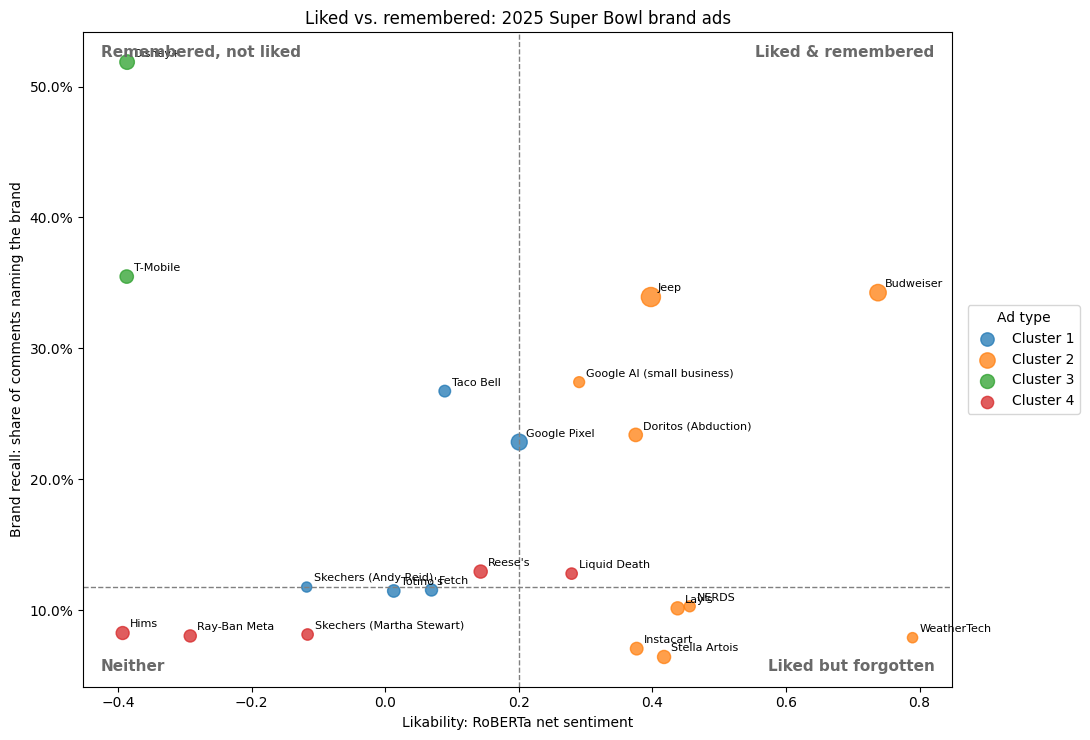

Medians: likability +0.20, brand recall 11.8%

Liked & remembered: Budweiser, Jeep, Doritos (Abduction), Google AI (small business), Liquid Death, Google Pixel
Liked but forgotten: WeatherTech, NERDS, Lay's, Stella Artois, Instacart
Neither: Fetch, Totino's, Skechers (Martha Stewart), Ray-Ban Meta, Hims
Remembered, not liked: Reese's, Taco Bell, Skechers (Andy Reid), Disney+, T-Mobile

Top-half Ad Meter ads with below-median brand recall:


,short_name,admeter_rank,admeter_score,net_sentiment_hf,brand_recall,message_fit_embed
3,Lay's,2,3.55,+0.44,10.1%,0.19
4,Stella Artois,4,3.51,+0.42,6.4%,0.17
6,Instacart,13,3.31,+0.38,7.1%,0.17
0,WeatherTech,20,3.13,+0.79,7.9%,0.17


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Names chosen after reading the cluster profiles.
CLUSTER_NAMES = {1: "Bittersweet and mixed", 2: "Crowd-pleasers",
                 3: "Brand backlash", 4: "Off-putting and forgettable"}

x_col, y_col = "net_sentiment_hf", "brand_recall"
x_mid, y_mid = analysis_ads[x_col].median(), analysis_ads[y_col].median()

fig, ax = plt.subplots(figsize=(11, 7.5))
for cluster, group in analysis_ads.groupby("cluster"):
    ax.scatter(group[x_col], group[y_col],
               s=30 + 4 * np.sqrt(group["n_comments"]),
               alpha=0.75, label=CLUSTER_NAMES[cluster])
for row in analysis_ads.itertuples():
    ax.annotate(row.short_name, (getattr(row, x_col), getattr(row, y_col)),
                xytext=(5, 4), textcoords="offset points", fontsize=8)

ax.axvline(x_mid, color="grey", linestyle="--", linewidth=1)
ax.axhline(y_mid, color="grey", linestyle="--", linewidth=1)
corners = {
    "Liked & remembered": (0.98, 0.98, "right", "top"),
    "Remembered, not liked": (0.02, 0.98, "left", "top"),
    "Liked but forgotten": (0.98, 0.02, "right", "bottom"),
    "Neither": (0.02, 0.02, "left", "bottom"),
}
for label, (x, y, ha, va) in corners.items():
    ax.text(x, y, label, transform=ax.transAxes, ha=ha, va=va,
            fontsize=11, fontweight="bold", color="dimgrey")

ax.set_xlabel("Likability: RoBERTa net sentiment")
ax.set_ylabel("Brand recall: share of comments naming the brand")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Liked vs. remembered: 2025 Super Bowl brand ads")
ax.legend(title="Ad type", loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/task_f_2x2.png", dpi=200, bbox_inches="tight")
plt.show()

liked = analysis_ads[x_col] >= x_mid
remembered = analysis_ads[y_col] >= y_mid
analysis_ads["quadrant"] = np.select(
    [liked & remembered, ~liked & remembered, liked & ~remembered],
    ["Liked & remembered", "Remembered, not liked", "Liked but forgotten"],
    default="Neither"
)

print(f"Medians: likability {x_mid:+.2f}, brand recall {y_mid:.1%}\n")
for quadrant, group in analysis_ads.groupby("quadrant"):
    print(f"{quadrant}: " + ", ".join(group["short_name"]))

rated = analysis_ads.dropna(subset=["admeter_score"])
if len(rated) >= 5:
    missed = rated[
        (rated["admeter_score"] >= rated["admeter_score"].median())
        & (rated["brand_recall"] < y_mid)
    ]
    print("\nTop-half Ad Meter ads with below-median brand recall:")
    display(
        missed.sort_values("admeter_score", ascending=False)
        [["short_name", "admeter_rank", "admeter_score", "net_sentiment_hf",
          "brand_recall", "message_fit_embed"]]
        .style.format({"admeter_rank": "{:.0f}", "admeter_score": "{:.2f}",
                       "net_sentiment_hf": "{:+.2f}", "brand_recall": "{:.1%}",
                       "message_fit_embed": "{:.2f}"})
    )

## What Drives Ad Meter vs. Brand Recall?

We fit the same small linear regression twice, once predicting Ad Meter score and once predicting brand recall. The predictors are:

- celebrity (0/1, from `ads.csv`)
- humor share (from Task B's dictionary)
- joy
- sadness

All variables are standardized, so coefficients are comparable within and across the two models. We use robust (HC3) standard errors.

With about 20 ads and four predictors this is descriptive, not a causal or predictive model. We compare the sign and relative size of each coefficient across the two outcomes; a feature that raises Ad Meter but not recall is a sign of an ad that is liked but forgotten. Predictors missing from `ads.csv` are dropped automatically.

In [ ]:
import statsmodels.api as sm

candidates = ["celebrity", "humor_share", "joy", "sadness"]
predictors = [
    c for c in candidates
    if analysis_ads[c].notna().sum() >= 10 and analysis_ads[c].nunique() > 1
]
print("Predictors used:", predictors)

def zscore(s):
    return (s - s.mean()) / s.std()

regressions = {}
for outcome in ["admeter_score", "brand_recall"]:
    d = analysis_ads[predictors + [outcome]].dropna()
    if len(d) < len(predictors) + 5:
        print(f"Skipping {outcome}: only {len(d)} complete rows.")
        continue
    X_reg = sm.add_constant(d[predictors].apply(zscore))
    regressions[outcome] = sm.OLS(zscore(d[outcome]), X_reg).fit(cov_type="HC3")

if regressions:
    reg_table = pd.concat(
        {o: pd.DataFrame({"coef": f.params, "p_value": f.pvalues}).drop("const")
         for o, f in regressions.items()},
        axis=1
    )
    display(reg_table.round(2))
    for o, f in regressions.items():
        print(f"{o}: n = {int(f.nobs)}, R² = {f.rsquared:.2f}")

Predictors used: ['celebrity', 'humor_share', 'joy', 'sadness']


admeter_score         brand_recall        
                     coef p_value         coef p_value
celebrity            0.02    0.92        -0.07    0.77
humor_share         -0.08    0.75        -0.40    0.06
joy                  0.69    0.02        -0.11    0.75
sadness             -0.06    0.93         0.06    0.73

admeter_score: n = 18, R² = 0.50
brand_recall: n = 21, R² = 0.22


In [ ]:
final_scorecard = scorecard.merge(
    analysis_ads[["video_id", "cluster", "quadrant"]], on="video_id", how="left"
)
final_scorecard["cluster_name"] = final_scorecard["cluster"].map(CLUSTER_NAMES)
final_scorecard.to_csv(f"{SAVE_DIR}/scorecard_final.csv", index=False)
correlations.to_csv(f"{SAVE_DIR}/task_f_correlations.csv", index=False)
print("Saved scorecard_final.csv and task_f_correlations.csv")

Saved scorecard_final.csv and task_f_correlations.csv


### Analysis: Validating the Scorecard

**Likability vs. Ad Meter.** Across the 18 brand ads with an Ad Meter score (Ad Meter did not rate the Google AI small-business spot or either Skechers spot), RoBERTa net sentiment has a Spearman correlation of +0.78 with Ad Meter (p < 0.001). VADER's is +0.69 and the like-weighted RoBERTa version's is +0.82. Our comment-based likability broadly agrees with the Ad Meter panel, so it can stand in for a panel when none exists. The method that was more accurate in our hand-labeled validation (RoBERTa) also agrees more with Ad Meter, and weighting by comment likes improves agreement further.

The disagreements are informative:

- We rank WeatherTech and NERDS about seven places higher than Ad Meter does among these 18 ads, but both rest on few comments (38 and 68).
- We rank Disney+ six places lower. Ad Meter put it mid-pack (2.81), while its comments are dominated by backlash against the company.
- We rank Google Pixel 4.5 places lower, consistent with Task C's finding that viewers' tears pull its sentiment down.

Commenters react to company news and emotional content in ways a live rating panel does not.

The two benchmarks also disagree with each other: Ad Meter and Kellogg grades correlate at only +0.31 (p = 0.21). Budweiser was #1 on Ad Meter but received a C from Kellogg. T-Mobile received an A from Kellogg but ranked 51st of 57 on Ad Meter. Liking an ad and judging its strategy are different things.

**Brand recall.** The refined dictionary raises brand recall from Task D's near-zero levels to between 6.4% (Stella Artois) and 51.9% (Disney+) across brand ads; Google Pixel rises from 0.2% to 22.8%. The ad rankings under the two dictionaries correlate at +0.56 (p = 0.009), so the ordering is partly stable but the levels depend heavily on the dictionary.

In our check of 20 matched comments, all named the intended brand or product and none were word-sense errors. One was channel self-promotion that happened to name Taco Bell, which our exact-match spam rules missed.

Brand recall is unrelated to both benchmarks: -0.08 with Kellogg grade and -0.09 with Ad Meter. Kellogg grades are brand-level letter grades, so a weak link there is partly expected. Neither benchmark measures whether viewers name the brand, which is the gap our scorecard fills.

**The pillars measure different things.** Likability and brand recall correlate at -0.17 (p = 0.47), so an ad can do well on one and poorly on the other; this is why a likability score alone is not enough. Message fit and brand recall correlate at +0.45 (p = 0.04). Part of that overlap is mechanical, because most titles contain the brand name. Message fit is not related to Kellogg grades (-0.31, p = 0.21).

### Analysis: Ad Types

K-means chose 4 clusters (silhouette 0.25, vs. 0.21 for 3). The grouping was stable across 10 random seeds (mean adjusted Rand index 0.97, minimum 0.89), but a silhouette of 0.25 means the clusters overlap. We named each cluster from its average profile:

| Cluster | Name | Profile | Ads |
|---|---|---|---|
| 1 | Bittersweet and mixed | Middling likability (+0.05), highest sadness (14%) | Google Pixel, Taco Bell, Fetch, Totino's, Skechers (Andy Reid) |
| 2 | Crowd-pleasers | Highest likability (+0.48) and joy (29%), average recall (18%) | WeatherTech, Budweiser, NERDS, Lay's, Stella Artois, Jeep, Instacart, Doritos, Google AI (small business) |
| 3 | Brand backlash | Lowest likability (-0.39), highest recall (44%), most anger (17%) | Disney+, T-Mobile |
| 4 | Off-putting and forgettable | Slightly negative (-0.08), lowest recall (10%), most disgust (14%) | Liquid Death, Reese's, Skechers (Martha Stewart), Ray-Ban Meta, Hims |

The sadness in cluster 1 has different sources: tears for Google Pixel, disappointment with the giveaway for Fetch. Hims is as disliked as T-Mobile and Disney+ but falls in cluster 4 because few of its comments name the brand (8.3%). With 21 ads, and only two in cluster 3, these clusters describe this year's ads; they are not a general typology.

### Analysis: Liked but Forgotten

The medians are +0.20 for likability and 11.8% for brand recall.

| Quadrant | Ads |
|---|---|
| Liked & remembered | Budweiser, Jeep, Doritos, Google AI (small business), Liquid Death, Google Pixel |
| Liked but forgotten | WeatherTech, NERDS, Lay's, Stella Artois, Instacart |
| Remembered, not liked | Reese's, Taco Bell, Skechers (Andy Reid), Disney+, T-Mobile |
| Neither | Fetch, Totino's, Skechers (Martha Stewart), Ray-Ban Meta, Hims |

The five "liked but forgotten" ads had positive comments, but only 6.4% to 10.3% of those comments named the brand. Using Ad Meter instead of our likability, four ads finished in the top half of Ad Meter with below-median brand recall:

- Lay's (#2 of 57, 10.1% recall)
- Stella Artois (#4, 6.4%)
- Instacart (#13, 7.1%)
- WeatherTech (#20, 7.9%)

These are the ads a likability ranking rewards and our scorecard questions. Budweiser shows the alternative: #1 on Ad Meter and 34.3% recall, the third highest of any brand ad.

The classification of Lay's and NERDS is sensitive, because both sit within two points of the recall median. Stella Artois and Instacart are clearly below it. Lay's comments often discussed the song (Task B); for Stella Artois we suspect the celebrities drew attention away from the beer, which the planned "celebrity only" LLM labels could test.

The "remembered, not liked" quadrant shows that high recall is not always good news. Disney+ (51.9%) and T-Mobile (35.5%) have the highest recall of any brand ad, but their comments name the brand mostly to criticize the company. Recall must therefore be read together with likability.

### Analysis: What Drives Ad Meter vs. Brand Recall

**Ad Meter model** (n = 18, R² = 0.50). Joy in the comments is the only clear predictor (+0.69, p = 0.02). Celebrity (+0.02), humor share (-0.08) and sadness (-0.06) are near zero.

**Brand recall model** (n = 21, R² = 0.22). Humor share has the largest coefficient (-0.40, p = 0.06): ads whose comment sections laugh the most had somewhat lower recall. Stella Artois (31% humor, 6.4% recall) and WeatherTech (24%, 7.9%) are examples. Joy (-0.11), celebrity (-0.07) and sadness (+0.06) are near zero.

Read together, joy goes with high Ad Meter scores but not with naming the brand, which is the pattern behind the "liked but forgotten" ads. A celebrity had no association with either outcome: Jeep's Harrison Ford spot reached 33.9% recall, while Stella Artois, with Matt Damon and David Beckham, had the lowest recall of any brand ad.

These estimates are imprecise, for three reasons:

- With 18 to 21 ads and four predictors, we read only the signs and relative sizes.
- Joy and Ad Meter both measure enjoyment, so the joy result partly restates the likability–Ad Meter correlation above.
- Humor share also counts mocking laughter.

We treat the difference between the two outcomes as a hypothesis to test with more Super Bowls.

# Task G: Recommendations for a Brand CMO

**"Ad Meter tells you if people liked your ad; we tell you if it worked."**

We advise a brand CMO or agency planning its next Super Bowl spot. A 30-second spot costs about $8M, and the most-cited measure of success, Ad Meter, measures only whether viewers liked the ad. Our scorecard adds two questions: did viewers name the brand, and did they talk about what the ad was trying to say?

## Recommendations

**1. Judge the ad on three numbers, not one.**
Our comment-based likability tracks Ad Meter closely (Spearman 0.78), but liking says nothing about whether viewers named the brand: likability and brand recall are unrelated (-0.17), and neither Ad Meter nor Kellogg grades predict recall. Four ads in the top half of Ad Meter fell below median brand recall: Lay's (#2), Stella Artois (#4), Instacart (#13) and WeatherTech (#20). Joy in the comments predicted Ad Meter scores but not recall, and featuring a celebrity predicted neither.

- **Action:** report likability, brand recall and message fit together, both in pre-testing and in the weeks after the game.
- **Clean the comments before scoring them.** Bot spam made up about a third of the Marvel trailer's comments and inflated its praise.
- **Weight comments by likes.** Like-weighted likability agreed best with Ad Meter (0.82), and it caught Fetch's problem: Fetch drops from +0.07 to -0.03 once the most-liked comments, which are complaints, count more.

**2. Audit the brand's baggage before airing, because it becomes the story.**
The four least-liked ads were the same under both sentiment methods: Hims, T-Mobile and Disney+ (all -0.39) and Ray-Ban Meta (-0.29). Their comments were about the company rather than the creative: Elon Musk and Starlink for T-Mobile, the drugs Hims sells, Disney's remakes and use of AI. These ads also drew the most anger and disgust: 18% anger for T-Mobile and 19% disgust for Hims, compared with about 4% each for Budweiser.

Disney+ and T-Mobile form their own "brand backlash" cluster: they had the highest brand recall of any brand ad (52% and 36%), but viewers named the brand to criticize it. T-Mobile's spot shows how far strategy and reception can split: Kellogg's panel graded it A, while Ad Meter viewers ranked it 51st of 57.

- **Action:** before the spot airs, list the controversies attached to the brand, its partners and its featured people.
- Avoid featuring the controversial element (for example, a partnership) at the center of the ad.
- Prepare a comment-response plan for launch week.

**3. Use emotion, but put the brand at the emotional peak.**
Budweiser's "First Delivery" is our most robust success: +0.74 under both methods, +0.80 like-weighted, 759 comments, 43% joy, #1 on Ad Meter, and 34% brand recall. The Clydesdales and the beer delivery are the brand, so viewers could not praise the story without naming it.

Lay's "The Little Farmer" was nearly as well liked (#2 on Ad Meter, 32% joy), but only 10% of its comments named Lay's. Google Pixel's "Dream Job" had the highest sadness share (21%), yet its comments were moved rather than critical, and 23% named Google or the Pixel, above the median, because the phone is part of the story.

- **Action:** write the brand or product into the emotional turn of the story, not only the end card.
- Measure emotional ads with an emotion model, not polarity alone.

**4. Treat the music as an asset, and attach the brand to it.**
Comments on Lay's "The Little Farmer" asked who sang the song and where to download it. NERDS commenters asked for a full version of Shaboozey's track. Across ads, positive reactions and music mentions appeared together more often than expected (lift 1.28: 37 comments vs. 29 expected). Yet both Lay's and NERDS landed among the "liked but forgotten" ads (about 10% recall each): the music got people talking, but not about the brand.

- **Action:** release the full track on streaming services on game day with the brand in its title or artwork, and link it in the video description, so viewer curiosity leads back to the brand.
- **Caveat:** the evidence here is modest, so we recommend this as a low-cost test.

## Which Conclusions Are Robust?

| Finding | Status | Why |
|---|---|---|
| Hims, T-Mobile, Disney+ and Ray-Ban Meta were the least liked | Robust | Lowest four under both VADER and RoBERTa; 137 to 401 comments each |
| Budweiser was the most liked | Robust | +0.74 under both methods, +0.80 like-weighted, 759 comments, #1 on Ad Meter |
| Comment likability tracks Ad Meter | Robust | Spearman 0.69 to 0.82 across 18 ads under all three likability versions |
| Liking and brand recall are different things | Robust | Correlation -0.17; recall unrelated to Ad Meter (-0.09) and Kellogg (-0.08) |
| Bot spam inflates apparent praise | Robust | Exact copies posted about 100 times each; about a third of the Marvel trailer's comments |
| Comments reflect attitudes toward the company, not only the ad | Robust | Seen in the topic model (Task B), sentiment errors (Task C), the message-fit review (Task E) and the backlash cluster (Task F) |
| Stella Artois and Instacart were liked but forgotten | Fairly robust | Top-half Ad Meter, recall well below the 11.8% median (6.4% and 7.1%) |
| Lay's and NERDS were liked but forgotten | Depends on threshold | Recall within two points of the median (10.1% and 10.3%) |
| WeatherTech was the most liked | Depends on sample | Highest score, but only 38 comments; Ad Meter ranked it 20th |
| Ranking of the two Skechers ads | Depends on method | They move about ten places between VADER and RoBERTa |
| Likability of emotional ads (Google Pixel) | Depends on method | Sad words in moved comments lower the sentiment score |
| Brand recall levels | Depends on dictionary | Levels differ sharply between Task D's regex and the refined dictionary; the rankings correlate at 0.56 |
| Message fit | Depends on proxy | Titles stand in for transcripts; BoW and embeddings correlate at 0.74 |
| Ad types (clusters) | Stable but weakly separated | Adjusted Rand index 0.97 across seeds, but silhouette only 0.25; one cluster has two ads |
| Celebrity, humor and emotion effects | Exploratory | 18 to 21 ads and four predictors; only joy → Ad Meter is clearly non-zero |

## Limitations

- **Small sample.** We planned three Super Bowls (2024 to 2026, about 160 ads) but analyzed 2025 only: 29 videos, 21 brand ads with enough comments, of which 18 have an Ad Meter score. Correlations, clusters and the regression are therefore low-powered.
- **Titles, not transcripts.** Message fit compares comments with the video title, not with what the ad actually said.
- **Brand recall is a proxy.** It counts unprompted brand mentions in comments, including complaints; it is not a recall survey, and it does not separate brand mentions from "celebrity only" mentions.
- **Coarse benchmarks.** Kellogg grades are letter grades given to the brand, not the spot, and Ad Meter did not rate three of our brand ads or any movie trailers.
- **Commenters are not the audience.** YouTube commenters choose to comment, and comments span months after the game, while the Ad Meter panel rated the ads in the days after it aired.
- **Data cleaning is partial.** Spam removal uses exact-match rules (one self-promotion comment slipped through our recall check), and non-English comments were not filtered.
- **Validation is small.** The 50 sentiment labels come from one person, and parts of Task B's review were AI-assisted.

## Next Steps

1. Add the 2024 and 2026 Super Bowls to reach about 160 ads, enough for a reliable regression.
2. Use ad transcripts as the intended message for message fit.
3. Use an LLM to label brand mentions and measure "celebrity only" mentions, starting with the liked-but-forgotten ads.
4. Validate brand recall against a prompted recall survey.
5. Apply the same scorecard to any campaign with public comments, not only the Super Bowl.

## Cost

Every task used only free, open-source packages and a free Colab T4 GPU, with no paid API calls ($0).